# Quantum Machine Learning untuk Cybersecurity
## Deteksi Intrusi Jaringan dengan Quantum Kernel pada Dataset HQC-2026
**Mata kuliah:** Quantum Computation for Cybersecurity, ITS

**Dataset:** HQC-2026 (*Hybrid Quantum-Classical Network Intrusion Detection Dataset*), Mendeley Data, DOI 10.17632/68rc9crgkj.1, CC BY 4.0.
Islam, I., Rabbi, I. R., Emon, T. H., Sahin Afridi, A., & Nur, F. (2026). Mendeley Data.

### Pertanyaan penelitian
1. **RQ1.** Apakah fitur QKD simulasi (`qber`, `sifted_key_rate`) benar-benar menambah kemampuan mendeteksi serangan, atau hanya membocorkan label?
2. **RQ2.** Pada fitur yang *jujur* (tanpa kebocoran), apakah quantum kernel (QSVC) mengungguli SVM klasik setelah keduanya dituning dengan anggaran yang sama?
3. **RQ3.** Bagaimana perilaku quantum kernel terhadap ukuran data, *shot noise*, dan biaya komputasi?
4. **RQ4.** Apakah kesimpulan bertahan pada pembanding klasik yang kuat, pada split waktu, dan pada **dataset lain tanpa fitur QKD** (NSL-KDD)?
5. **RQ5.** Dari mana `qber` berasal secara fisik (BB84 + penyadap), dan seberapa tahan quantum kernel terhadap **noise** perangkat nyata?

### Peta notebook
| Bagian | Isi | Materi dosen |
|---|---|---|
| 1 | Setup dan verifikasi berkas (SHA-256) | Bab 6 (5.1, App. C) |
| 2-3 | Data, audit mutu, audit *target leakage* | Bab 6 (3, 6) |
| 4 | **BB84 dan penyadap:** asal fisik QBER | Bab 6 (1.2) |
| 5 | Penyiapan fitur: set fitur, PCA ke 4 dimensi, scaling sudut | Bab 6 (7) |
| 6 | Mesin quantum kernel, validasi vs Qiskit resmi, biaya sirkuit | Bab 4 (3, 9, 13), Bab 6 (7.4) |
| 7 | Eksperimen 1: ablation fitur | Bab 6 (9.1) |
| 8 | Eksperimen 2: tuning adil dan kurva belajar | Bab 4 (15), Bab 6 (9.2-9.4) |
| 9 | Visualisasi kernel dan *geometric difference* | Bab 4 (1-2) |
| 10 | Eksperimen 3: *shot noise* | Bab 4 (5, 13) |
| 11 | Eksperimen 4: **noise perangkat** (depolarizing dan fake backend IBM) | Bab 4 (7) |
| 12 | Eksperimen 5: VQC | Bab 6 (9.5) |
| 13 | Eksperimen 6: pembanding klasik kuat, serangan yang sulit | Bab 6 (4.4) |
| 14 | Eksperimen 7: split waktu | Bab 6 (6.5) |
| 15 | Eksperimen 8: **dataset kedua NSL-KDD** (tanpa QKD) | Bab 6 (9.4) |
| 16 | Opsional: satu elemen kernel di IBM Quantum asli | Bab 4 (6) |
| 17 | Ringkasan otomatis dan kesimpulan | Bab 6 (11) |

## 1. Setup

In [2]:
# Pasang paket (versi dipatok sesuai Bab 6). Jalankan sekali, lalu Runtime > Restart session bila diminta.
!pip install -q "qiskit-machine-learning==0.9.1" pyarrow seaborn pylatexenc qiskit-aer qiskit-ibm-runtime

In [3]:
import os, sys, time, hashlib, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score, confusion_matrix, roc_auc_score)
warnings.filterwarnings("ignore")

# ---------- KONFIGURASI (ubah hanya bagian ini) ----------
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/Quantum"          # folder berisi berkas Parquet
else:
    DATA_DIR = os.environ.get("QML_DATA_DIR", ".")       # Jupyter lokal / Kaggle: sesuaikan
OUT_DIR = os.environ.get("QML_OUT_DIR", DATA_DIR)        # tempat menyimpan CSV dan gambar hasil

V3   = os.path.join(DATA_DIR, "SUPER_ENRICHED_hybrid_dataset_v3.parquet")      # berkas utama
BASE = os.path.join(DATA_DIR, "final_hybrid_cybersecurity_dataset.parquet")    # berkas dengan timestamp (untuk split waktu)

SEEDS   = [0, 1, 2, 3, 4]          # pengulangan eksperimen
N_TEST  = 100                       # sampel test per kelas (seimbang)
SIZES   = [12, 24, 48, 96, 192]     # ukuran train per kelas untuk kurva belajar
RUN_VQC = True                      # VQC
RUN_NOISE = True                    # noise perangkat (butuh qiskit-aer, qiskit-ibm-runtime)
RUN_TIME_SPLIT = True               # split waktu (butuh berkas base)
RUN_NSLKDD = True                   # dataset kedua NSL-KDD (diunduh otomatis jika ada internet)
RUN_IBM = False                     # perangkat IBM asli (butuh akun IBM Quantum, default mati)
FAST = os.environ.get("QML_FAST", "0") == "1"   # mode uji cepat (hanya untuk debugging, biarkan 0)
RF_SUB, RF_TREES, VQC_ITERS, NOISE_SEEDS, NOISE_N = 50000, 100, 100, 3, 12
if FAST:
    SEEDS, SIZES, N_TEST = [0, 1], [12, 48], 40
    RF_SUB, RF_TREES, VQC_ITERS, NOISE_SEEDS, NOISE_N = 8000, 30, 25, 1, 6
# ---------------------------------------------------------

import sklearn, qiskit, qiskit_machine_learning as qml
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qml.__version__)
print("Berkas v3 ada:", os.path.exists(V3), "| berkas base ada:", os.path.exists(BASE))

Mounted at /content/drive
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | sklearn 1.6.1
qiskit 2.6.1 | qiskit-machine-learning 0.9.1
Berkas v3 ada: True | berkas base ada: True


In [4]:
# Verifikasi integritas berkas dengan SHA-256 (nilai acuan dari Lampiran C Bab 6)
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

EXPECTED_V3 = "aa2aefc0e8586c56e315a36b6c9fa922f36b5c21c3390bf5c2ea2eeab9995ec1"
got = sha256(V3)
print("SHA-256 v3 :", got)
print("Cocok dengan Bab 6:", got == EXPECTED_V3)

SHA-256 v3 : aa2aefc0e8586c56e315a36b6c9fa922f36b5c21c3390bf5c2ea2eeab9995ec1
Cocok dengan Bab 6: True


## 2. Data dan audit mutu
Berkas **Parquet** adalah format tabel berbasis kolom (terkompresi), jadi kita bisa membaca hanya kolom yang diperlukan. Kita pakai berkas **v3**.

`target = 1` berarti serangan (semua label selain `Benign`), `0` trafik normal. Kolom dibagi tiga kelompok:
- **RAW:** 78 fitur aliran jaringan klasik (gaya CICFlowMeter), yaitu semua kolom sebelum `qber`.
- **QKD:** `qber`, `sifted_key_rate` (hasil **simulasi** BB84, bukan dari komputer kuantum).
- **LEAK:** flag semantik yang diturunkan dari jenis serangan.

In [5]:
cols_all = list(pd.read_parquet(V3, columns=None).columns[:0]) if False else None   # (tidak dipakai)
import pyarrow.parquet as pq
schema_cols = pq.ParquetFile(V3).schema.names
RAW  = schema_cols[:schema_cols.index("qber")]                     # 78 fitur jaringan klasik
QKD  = ["qber", "sifted_key_rate"]
LEAK = ["is_anomalous_qkd", "is_ddos_attack", "is_bruteforce_attack", "is_web_attack_specific", "matches_modern_attack_type"]
EXTRA = ["fidelity", "qber_delta"]
print("Jumlah kolom total:", len(schema_cols), "| RAW:", len(RAW))

df = pd.read_parquet(V3, columns=RAW + QKD + LEAK + EXTRA + ["label"])
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
df["target"] = (df["label"] != "Benign").astype(int)

# Keluarga serangan (aturan pemetaan dari Bab 6 bagian 4.3, ditulis eksplisit)
FAMILY = {"Benign": "Benign", "Bot-Stealth": "Bot", "Bot-Aggressive": "Bot", "Infilteration": "Infiltration",
          "FTP-BruteForce": "FTP brute force", "SSH-Bruteforce": "SSH brute force",
          "DoS attacks-SlowHTTPTest": "DoS", "DoS attacks-Slowloris": "DoS", "DoS attacks-GoldenEye": "DoS", "DoS attacks-Hulk": "DoS",
          "DDOS attack-HOIC": "DDoS", "DDOS attack-LOIC-UDP": "DDoS",
          "Brute Force -Web": "Web attack", "Brute Force -XSS": "Web attack", "SQL Injection": "Web attack"}
df["family"] = df["label"].map(FAMILY)

print("Bentuk data:", df.shape, "| nilai kosong:", int(df.isna().sum().sum()), "| baris duplikat penuh:", int(df.duplicated().sum()))
print("Akurasi jika SELALU menjawab Benign:", round((df.target == 0).mean() * 100, 2), "%  (inilah mengapa accuracy menipu)")
display(df["label"].value_counts().to_frame("jumlah").assign(persen=lambda d: (d.jumlah / len(df) * 100).round(2)))

Jumlah kolom total: 96 | RAW: 78
Bentuk data: (233844, 90) | nilai kosong: 0 | baris duplikat penuh: 0
Akurasi jika SELALU menjawab Benign: 75.99 %  (inilah mengapa accuracy menipu)


,jumlah,persen
label,,
Benign,177693,75.99
Infilteration,15620,6.68
Bot-Stealth,10123,4.33
Bot-Aggressive,10103,4.32
FTP-BruteForce,5826,2.49
SSH-Bruteforce,5442,2.33
DoS attacks-SlowHTTPTest,2755,1.18
DoS attacks-Slowloris,2449,1.05
DDOS attack-HOIC,1342,0.57


## 3. Audit target leakage (menjawab RQ1)
**Aturan emas:** fitur dianggap bocor jika diturunkan dari label, baru tersedia setelah label diketahui, atau memakai informasi masa depan.

Tiga pemeriksaan: (a) relasi deterministik antar-fitur, (b) kemampuan membedakan kelas **satu fitur saja** (AUC, 0,5 = acak, 1,0 = sempurna), (c) apakah satu aturan sederhana sudah cukup.

In [6]:
# (a) Relasi deterministik: fidelity dan qber_delta tidak menambah informasi apa pun
print("max |fidelity - (1 - qber)|      :", float(np.abs(df.fidelity - (1 - df.qber)).max()))
print("max |qber_delta - (qber - 0.01)| :", float(np.abs(df.qber_delta - (df.qber - 0.01)).max()))

# (b) AUC satu fitur: seberapa kuat tiap fitur memisahkan benign vs serangan?
sm = df.sample(60000, random_state=0)
auc = {}
for c in RAW + QKD + LEAK:
    if sm[c].nunique() > 1:
        a = roc_auc_score(sm.target, sm[c]); auc[c] = max(a, 1 - a)     # arah tidak penting, ambil sisi >= 0.5
auc = pd.Series(auc).sort_values(ascending=False)
tipe = ["LEAK" if c in LEAK else "QKD" if c in QKD else "jaringan" for c in auc.index]
tabel_auc = pd.DataFrame({"AUC satu fitur": auc.round(4), "kelompok": tipe})
print("\n10 fitur terkuat:"); display(tabel_auc.head(10))
print("Fitur jaringan terkuat:", tabel_auc[tabel_auc.kelompok == "jaringan"].head(1).index[0],
      "-> AUC", float(tabel_auc[tabel_auc.kelompok == "jaringan"].iloc[0, 0]))
print("sifted_key_rate AUC:", float(tabel_auc.loc["sifted_key_rate", "AUC satu fitur"]))

max |fidelity - (1 - qber)|      : 0.0
max |qber_delta - (qber - 0.01)| : 0.0

10 fitur terkuat:


,AUC satu fitur,kelompok
qber,1.0000,QKD
is_anomalous_qkd,0.9956,LEAK
flow_iat_max,0.7077,jaringan
fwd_iat_max,0.7018,jaringan
fwd_iat_mean,0.6915,jaringan
flow_iat_mean,0.6856,jaringan
flow_duration,0.6746,jaringan
fwd_iat_tot,0.6708,jaringan
fwd_iat_min,0.6670,jaringan
idle_min,0.6659,jaringan


Fitur jaringan terkuat: flow_iat_max -> AUC 0.7077
sifted_key_rate AUC: 0.5017


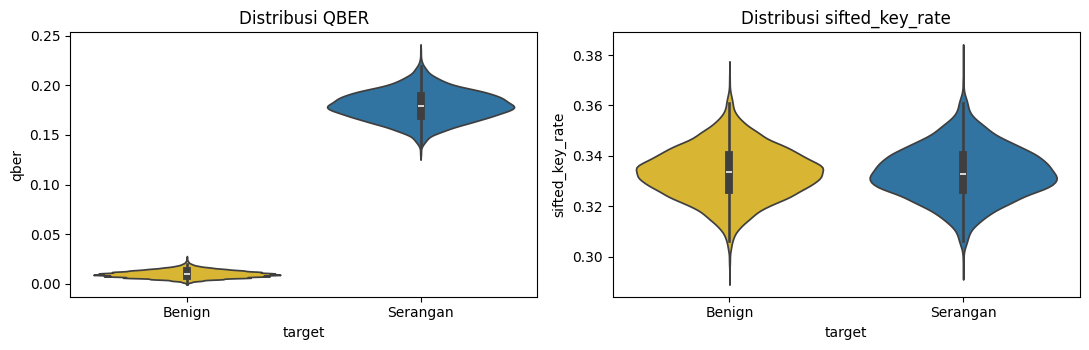

qber maksimum Benign  : 0.032
qber minimum Serangan : 0.1201
Aturan 1 baris 'qber > 0.05 berarti serangan' -> akurasi 100.0 % pada SELURUH data


In [7]:
# (c) Distribusi QBER dan aturan satu baris
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
s2 = df.sample(20000, random_state=0)
sns.violinplot(data=s2, x="target", y="qber", ax=ax[0], palette=["#f5c518", "#1f77b4"]); ax[0].set_xticklabels(["Benign", "Serangan"]); ax[0].set_title("Distribusi QBER")
sns.violinplot(data=s2, x="target", y="sifted_key_rate", ax=ax[1], palette=["#f5c518", "#1f77b4"]); ax[1].set_xticklabels(["Benign", "Serangan"]); ax[1].set_title("Distribusi sifted_key_rate")
plt.tight_layout(); plt.show()

print("qber maksimum Benign  :", round(df.loc[df.target == 0, "qber"].max(), 4))
print("qber minimum Serangan :", round(df.loc[df.target == 1, "qber"].min(), 4))
print("Aturan 1 baris 'qber > 0.05 berarti serangan' -> akurasi", round(((df.qber > 0.05).astype(int) == df.target).mean() * 100, 2), "% pada SELURUH data")

**Temuan RQ1.** `qber` memisahkan kelas secara sempurna (tidak ada tumpang tindih), sedangkan `sifted_key_rate` tidak membedakan kelas sama sekali. Satu aturan sederhana pada `qber` sudah 100% benar. Nilai QBER tampaknya dibangkitkan **dari label** saat simulasi, jadi skor tinggi pada model yang memakainya **bukan** bukti kemampuan mendeteksi serangan nyata. Flag semantik adalah turunan label (kebocoran langsung). Karena itu benchmark yang jujur memakai **hanya fitur jaringan**, sedangkan `qber`, `sifted_key_rate`, dan flag dipakai untuk ablation dan demonstrasi jebakan.

## 4. Dari mana QBER berasal? Simulasi BB84 dengan penyadap (RQ5)
Dataset menyebut fitur QKD berasal dari **simulasi protokol BB84**. Supaya `qber` tidak jadi kotak hitam, kita simulasikan sendiri:
1. Alice mengirim bit acak dengan basis acak (Z atau X), Bob mengukur dengan basis acak.
2. Bit dengan basis **berbeda** dibuang (*sifting*), sisanya menjadi *sifted key*.
3. **QBER** = proporsi bit sifted yang berbeda antara Alice dan Bob.
4. Penyadap Eve (*intercept-resend*) mengukur qubit dengan basis acak lalu mengirim ulang. Pada basis yang salah ia mengacak bit, sehingga menimbulkan error. Jika Eve menyadap sebagian *f* dari qubit, QBER ≈ **0,25 · f** (ditambah noise kanal).
5. Keamanan: QBER di atas ambang (±11%) berarti kunci tidak aman dan dibuang.

**Pelajaran penting untuk cybersecurity:** QBER adalah properti **kanal kuantum**, yaitu mendeteksi *penyadapan pada kunci*. Ia bukan properti **aliran jaringan klasik** seperti DDoS atau brute force. Jadi korelasi sempurna QBER dengan label serangan di HQC-2026 hanya bisa terjadi jika nilai QBER dibangkitkan dari label, bukan diukur dari trafik.

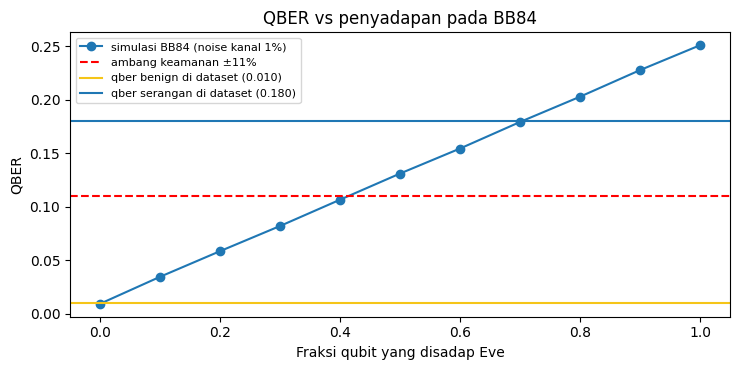

Tanpa penyadap : QBER simulasi = 0.009 (dataset benign 0.010)
Eve menyadap semua qubit : QBER simulasi = 0.251 (teori 0,25 + noise)
QBER serangan di dataset (0.180) setara dengan Eve menyadap sekitar 68% qubit.


In [8]:
def bb84(n=20000, eve_fraction=0.0, p_noise=0.0, seed=0):
    rng = np.random.default_rng(seed)
    a_bit, a_bas, b_bas = rng.integers(0, 2, n), rng.integers(0, 2, n), rng.integers(0, 2, n)   # basis: 0 = Z, 1 = X
    bit, bas = a_bit.copy(), a_bas.copy()                       # keadaan qubit yang dikirim Alice
    hit = rng.random(n) < eve_fraction                            # qubit yang disadap Eve (intercept-resend)
    e_bas = rng.integers(0, 2, n)
    e_bit = np.where(e_bas == a_bas, a_bit, rng.integers(0, 2, n))   # basis salah -> hasil ukur Eve acak
    bit, bas = np.where(hit, e_bit, bit), np.where(hit, e_bas, bas)  # Eve mengirim ulang sesuai hasil ukurnya
    bit = bit ^ (rng.random(n) < p_noise).astype(int)             # noise kanal: pembalikan bit
    b_bit = np.where(b_bas == bas, bit, rng.integers(0, 2, n))    # Bob: basis cocok -> bit benar, tidak cocok -> acak
    sift = a_bas == b_bas                                         # sifting: simpan hanya basis yang sama
    return float((a_bit[sift] != b_bit[sift]).mean()), float(sift.mean())

fr = np.linspace(0, 1, 11)
sim_q = [np.mean([bb84(eve_fraction=f, p_noise=0.01, seed=s)[0] for s in range(5)]) for f in fr]
q_benign, q_serang = df.loc[df.target == 0, "qber"].mean(), df.loc[df.target == 1, "qber"].mean()
f_ekuivalen = (q_serang - q_benign) / 0.25
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(fr, sim_q, "o-", label="simulasi BB84 (noise kanal 1%)"); ax.axhline(0.11, ls="--", c="r", label="ambang keamanan ±11%")
ax.axhline(q_benign, c="#f5c518", label=f"qber benign di dataset ({q_benign:.3f})"); ax.axhline(q_serang, c="#1f77b4", label=f"qber serangan di dataset ({q_serang:.3f})")
ax.set_xlabel("Fraksi qubit yang disadap Eve"); ax.set_ylabel("QBER"); ax.set_title("QBER vs penyadapan pada BB84"); ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "gambar_BB84.png"), dpi=150); plt.show()
print(f"Tanpa penyadap : QBER simulasi = {sim_q[0]:.3f} (dataset benign {q_benign:.3f})")
print(f"Eve menyadap semua qubit : QBER simulasi = {sim_q[-1]:.3f} (teori 0,25 + noise)")
print(f"QBER serangan di dataset ({q_serang:.3f}) setara dengan Eve menyadap sekitar {f_ekuivalen * 100:.0f}% qubit.")

**Cara membaca.** QBER benign di dataset (±0,01) cocok dengan kanal kuantum sehat bernoise 1%. QBER serangan (±0,18) cocok dengan penyadapan hebat. Jadi dataset ini pada dasarnya menyuntikkan *skenario penyadapan* untuk semua baris berlabel serangan. Itu memang menjelaskan keterpisahan sempurnanya, sekaligus menegaskan bahwa fitur ini **tidak dihasilkan oleh perilaku aliran jaringan**, sehingga tidak boleh dipakai sebagai bukti kemampuan mendeteksi DDoS, brute force, dan sebagainya.

## 5. Penyiapan fitur
**Mengapa jumlah fitur harus kecil?** Pada feature map sederhana satu fitur memakai satu qubit, dan kernel untuk *n* sampel butuh sekitar *n²* kemiripan. Jadi kita pakai **4 fitur = 4 qubit**.

Bagaimana memilih 4 fitur jujur dari 78 fitur jaringan? Kita bandingkan tiga cara:
- **A** : 4 fitur dipilih manual (`flow_pkts/s`, `pkt_len_mean`, `flow_duration`, `tot_fwd_pkts`).
- **A-PCA** : 78 fitur diringkas jadi 4 komponen utama (PCA). Tanpa label, jadi tidak ada kebocoran.
- **A-ANOVA** : 4 fitur dengan skor ANOVA-F tertinggi (memakai label **train saja**).

Fitur lain untuk ablation: **B** = QKD saja, **C** = 2 klasik + QKD (set Bab 6), **D** = C + flag bocor (hanya demo jebakan).

**Urutan wajib:** split dulu, sampling kemudian, scaler/PCA/seleksi hanya dipelajari dari data train. Data jaringan berekor sangat panjang (hingga jutaan), jadi diberi transformasi log bertanda sebelum scaling. Terakhir tiap fitur diskalakan ke [0, π] karena nilainya dipakai sebagai **sudut** gerbang rotasi.

In [9]:
FLOW4 = ["flow_pkts/s", "pkt_len_mean", "flow_duration", "tot_fwd_pkts"]
FLOW2 = ["flow_pkts/s", "pkt_len_mean"]

# 1) Split dulu (80/20, stratifikasi). Test pool TIDAK disentuh untuk keperluan apa pun selain evaluasi.
train_pool, test_pool = train_test_split(df, test_size=0.20, stratify=df["target"], random_state=42)

def slog(x):                       # log bertanda: sama dengan log1p untuk nilai >= 0, aman untuk nilai negatif
    return np.sign(x) * np.log1p(np.abs(x))

# 2) Pelajari PCA dan seleksi ANOVA HANYA dari train pool (20.000 baris acak)
fit_pool = train_pool.sample(20000, random_state=0)
sc_all   = StandardScaler().fit(slog(fit_pool[RAW].values))
pca4     = PCA(n_components=4, random_state=0).fit(sc_all.transform(slog(fit_pool[RAW].values)))
sel4     = SelectKBest(f_classif, k=4).fit(slog(fit_pool[RAW].values), fit_pool["target"])
ANOVA_COLS = [RAW[i] for i in sel4.get_support(indices=True)]
print("Varians dijelaskan 4 komponen PCA:", pca4.explained_variance_ratio_.round(3), "| total", pca4.explained_variance_ratio_.sum().round(3))
print("4 fitur ANOVA terbaik            :", ANOVA_COLS)

def raw_features(kind, d):
    # Matriks fitur MENTAH (belum diskalakan ke sudut) untuk tiap set fitur
    if kind == "A":        return slog(d[FLOW4].values)
    if kind == "A-PCA":    return pca4.transform(sc_all.transform(slog(d[RAW].values)))
    if kind == "A-ANOVA":  return slog(d[ANOVA_COLS].values)
    if kind == "B":        return d[QKD].values
    if kind == "C":        return np.hstack([slog(d[FLOW2].values), d[QKD].values])
    if kind == "D":        return np.hstack([slog(d[FLOW2].values), d[QKD].values, d[LEAK[:3]].values])
    raise ValueError(kind)

def sample_each(frame, n, seed):
    # ambil n baris per kelas, lalu acak urutannya
    return (frame.groupby("target", group_keys=False).sample(n=n, random_state=seed).sample(frac=1, random_state=seed))

def prepare(kind, n_train, seed, n_test=N_TEST):
    tr = sample_each(train_pool, n_train, seed)
    te = sample_each(test_pool, n_test, seed + 1000)
    Xtr, Xte = raw_features(kind, tr), raw_features(kind, te)
    mm = MinMaxScaler(feature_range=(0, np.pi)).fit(Xtr)          # scaler dipelajari dari TRAIN saja
    return mm.transform(Xtr), tr["target"].values, mm.transform(Xte), te["target"].values, tr, te

def evaluate(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(bal_acc=balanced_accuracy_score(y, pred), macro_f1=f1_score(y, pred, average="macro"),
                recall_serangan=recall_score(y, pred), fpr=fp / (fp + tn))

Varians dijelaskan 4 komponen PCA: [0.362 0.12  0.088 0.07 ] | total 0.64
4 fitur ANOVA terbaik            : ['flow_iat_mean', 'flow_iat_max', 'fwd_iat_mean', 'fwd_seg_size_min']


## 6. Mesin quantum kernel
**Ide:** feature map $U_\phi(x)$ mengubah vektor data menjadi keadaan kuantum $|\phi(x)\rangle$, dan kemiripan dua data adalah
$$K(x,z)=|\langle\phi(x)|\phi(z)\rangle|^2 .$$
Matriks kernel ini dipakai oleh SVM klasik (`kernel="precomputed"`), persis alur Bab 4.

**Dua cara menghitungnya, hasilnya sama:**
1. *Resmi:* `FidelityQuantumKernel` + `QSVC` dari Qiskit (menghitung O(n²) rangkaian satu per satu, lambat).
2. *Cepat:* menghitung vektor keadaan (*statevector*) setiap data **sekali**, lalu $K = |S S^\dagger|^2$. Ini setara dengan simulator ideal (tanpa noise, shots tak terhingga), tetapi ratusan kali lebih cepat, sehingga kita bisa mengulang eksperimen banyak kali.

Kita **buktikan** keduanya sama di sel berikut.

In [10]:
from qiskit.circuit.library import zz_feature_map, z_feature_map
from qiskit.quantum_info import Statevector

FEATURE_MAPS = {
    "ZZ reps=1 linear": lambda q: zz_feature_map(q, reps=1, entanglement="linear"),
    "ZZ reps=2 linear": lambda q: zz_feature_map(q, reps=2, entanglement="linear"),
    "ZZ reps=1 full":   lambda q: zz_feature_map(q, reps=1, entanglement="full"),
    "Z reps=2":         lambda q: z_feature_map(q, reps=2),
}

def q_states(fm, X):
    # vektor keadaan tiap baris data: |phi(x)> = U(x)|0...0>
    out = np.empty((len(X), 2 ** fm.num_qubits), dtype=complex)
    for i, row in enumerate(X):
        out[i] = Statevector(fm.assign_parameters(list(row))).data
    return out

def q_kernel(SA, SB):
    # K[i,j] = |<phi(a_i)|phi(b_j)>|^2
    return np.abs(SA.conj() @ SB.T) ** 2

In [11]:
# VALIDASI: kernel cepat harus sama dengan FidelityQuantumKernel resmi, dan prediksi QSVC resmi harus sama
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC

Xtr, ytr, Xte, yte, _, _ = prepare("A-PCA", 12, seed=0, n_test=20)
fm4 = FEATURE_MAPS["ZZ reps=1 linear"](4)
K_resmi = FidelityQuantumKernel(feature_map=fm4).evaluate(Xtr)
S_tr = q_states(fm4, Xtr); K_cepat = q_kernel(S_tr, S_tr)
print("Selisih maksimum kernel resmi vs cepat:", float(np.abs(K_resmi - K_cepat).max()))

p_resmi = QSVC(quantum_kernel=FidelityQuantumKernel(feature_map=fm4)).fit(Xtr, ytr).predict(Xte)
p_cepat = SVC(kernel="precomputed").fit(K_cepat, ytr).predict(q_kernel(q_states(fm4, Xte), S_tr))
print("Prediksi QSVC resmi == prediksi kernel cepat:", bool((p_resmi == p_cepat).all()))

Selisih maksimum kernel resmi vs cepat: 5.025979632478084e-12
Prediksi QSVC resmi == prediksi kernel cepat: True


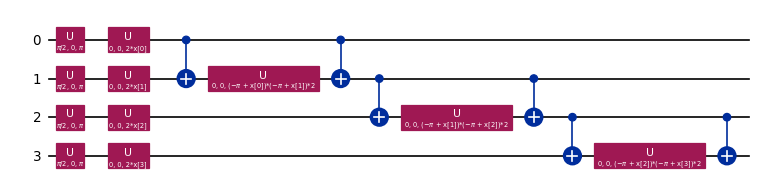

In [12]:
# Tampilkan sirkuit feature map agar mudah dijelaskan
try:
    display(FEATURE_MAPS["ZZ reps=1 linear"](4).decompose().draw("mpl", scale=0.6))
except Exception:
    print(FEATURE_MAPS["ZZ reps=1 linear"](4).decompose().draw("text"))

In [13]:
# BIAYA SIRKUIT (Bab 6 bagian 9.3): jumlah qubit, kedalaman (depth), gerbang 2-qubit, dan jumlah evaluasi sirkuit
from qiskit import transpile
from qiskit.circuit.library import unitary_overlap

rows = []
for q in [4, 7]:
    for name, build in FEATURE_MAPS.items():
        f0, f1 = build(q), build(q); rg = np.random.default_rng(0)       # dua titik data berbeda (jika sama, sirkuit saling menghapus)
        ov = unitary_overlap(f0.assign_parameters(rg.uniform(0, np.pi, q)), f1.assign_parameters(rg.uniform(0, np.pi, q))); ov.measure_all()   # sirkuit overlap seperti di Bab 4
        t = transpile(ov, basis_gates=["cx", "u"], optimization_level=0)
        rows.append(dict(feature_map=name, qubit=q, depth_overlap=t.depth(),
                         gerbang_2qubit=t.count_ops().get("cx", 0)))
biaya = pd.DataFrame(rows)
display(biaya)

# Jumlah evaluasi sirkuit kernel jika dijalankan satu per satu (cara resmi / perangkat nyata)
n_te = 2 * N_TEST
ev = pd.DataFrame({"train_per_kelas": SIZES})
ev["train_total"] = ev.train_per_kelas * 2
ev["pasangan_train n(n-1)/2"] = ev.train_total * (ev.train_total - 1) // 2
ev["pasangan_test t*n"] = n_te * ev.train_total
ev["total_sirkuit"] = ev["pasangan_train n(n-1)/2"] + ev["pasangan_test t*n"]
display(ev)

,feature_map,qubit,depth_overlap,gerbang_2qubit
0,ZZ reps=1 linear,4,23,12
1,ZZ reps=2 linear,4,39,24
2,ZZ reps=1 full,4,35,24
3,Z reps=2,4,9,0
4,ZZ reps=1 linear,7,41,24
5,ZZ reps=2 linear,7,57,48
6,ZZ reps=1 full,7,71,84
7,Z reps=2,7,9,0


,train_per_kelas,train_total,pasangan_train n(n-1)/2,pasangan_test t*n,total_sirkuit
0,12,24,276,4800,5076
1,24,48,1128,9600,10728
2,48,96,4560,19200,23760
3,96,192,18336,38400,56736
4,192,384,73536,76800,150336


## 7. Eksperimen 1: ablation fitur (RQ1 dan RQ2 awal)
Untuk tiap set fitur, jalankan **RBF-SVM** dan **QSVC** pada data, fitur, dan split yang identik, dengan **5 seed**. Ukuran train 24 per kelas (48 total), test 100 per kelas.
Pengaturan di sini masih *default* (ZZ reps=1, α=1, C=1) (belum dituning); tuning ada di Eksperimen 2.

In [14]:
def run_rbf(Xtr, ytr, Xte):
    t = time.time(); m = SVC(kernel="rbf", class_weight="balanced").fit(Xtr, ytr); fit = time.time() - t
    t = time.time(); p = m.predict(Xte); return p, fit, time.time() - t

def run_qk(Xtr, ytr, Xte, fm_name="ZZ reps=1 linear"):
    fm = FEATURE_MAPS[fm_name](Xtr.shape[1])
    t = time.time(); S = q_states(fm, Xtr); K = q_kernel(S, S)
    m = SVC(kernel="precomputed", class_weight="balanced").fit(K, ytr); fit = time.time() - t
    t = time.time(); p = m.predict(q_kernel(q_states(fm, Xte), S)); return p, fit, time.time() - t

SETS = {"A": "A: 4 klasik manual", "A-PCA": "A-PCA: 78 fitur -> PCA 4", "A-ANOVA": "A-ANOVA: 4 fitur terbaik",
        "B": "B: QKD saja", "C": "C: 2 klasik + QKD", "D": "D: C + flag bocor"}
rows = []
for kind, label in SETS.items():
    for seed in SEEDS:
        Xtr, ytr, Xte, yte, _, _ = prepare(kind, 24, seed)
        for model, fn in [("RBF-SVM", run_rbf), ("QSVC", run_qk)]:
            p, fit, pred_t = fn(Xtr, ytr, Xte)
            rows.append(dict(eksperimen="E1", set=label, kind=kind, model=model, seed=seed, n_per_kelas=24,
                             qubit=Xtr.shape[1], waktu_fit=fit, waktu_prediksi=pred_t, **evaluate(yte, p)))
E1 = pd.DataFrame(rows); E1.to_csv(os.path.join(OUT_DIR, "hasil_E1_ablation.csv"), index=False)
t1 = E1.groupby(["set", "model"])[["bal_acc", "macro_f1", "recall_serangan", "fpr", "waktu_fit"]].agg(["mean", "std"]).round(3)
display(t1)

bal_acc        macro_f1         \
                                    mean    std     mean    std   
set                      model                                    
A-ANOVA: 4 fitur terbaik QSVC      0.641  0.039    0.636  0.047   
                         RBF-SVM   0.654  0.026    0.647  0.029   
A-PCA: 78 fitur -> PCA 4 QSVC      0.590  0.050    0.588  0.050   
                         RBF-SVM   0.595  0.044    0.585  0.045   
A: 4 klasik manual       QSVC      0.616  0.038    0.610  0.040   
                         RBF-SVM   0.572  0.046    0.552  0.031   
B: QKD saja              QSVC      0.814  0.041    0.813  0.041   
                         RBF-SVM   1.000  0.000    1.000  0.000   
C: 2 klasik + QKD        QSVC      0.844  0.019    0.844  0.019   
                         RBF-SVM   0.999  0.002    0.999  0.002   
D: C + flag bocor        QSVC      0.953  0.006    0.953  0.006   
                         RBF-SVM   0.997  0.004    0.997  0.004   

                                 recall_serangan           fpr         \
                                            mean    std   mean    std   
set                      model                                          
A-ANOVA: 4 fitur terbaik QSVC              0.588  0.131  0.306  0.074   
                         RBF-SVM           0.528  0.086  0.220  0.058   
A-PCA: 78 fitur -> PCA 4 QSVC              0.614  0.108  0.434  0.044   
                         RBF-SVM           0.498  0.153  0.308  0.139   
A: 4 klasik manual       QSVC              0.570  0.097  0.338  0.154   
                         RBF-SVM           0.376  0.058  0.232  0.144   
B: QKD saja              QSVC              0.832  0.078  0.204  0.129   
                         RBF-SVM           1.000  0.000  0.000  0.000   
C: 2 klasik + QKD        QSVC              0.826  0.055  0.138  0.040   
                         RBF-SVM           1.000  0.000  0.002  0.004   
D: C + flag bocor        QSVC              0.946  0.015  0.040  0.019   
                         RBF-SVM           1.000  0.000  0.006  0.009   

                                 waktu_fit         
                                      mean    std  
set                      model                     
A-ANOVA: 4 fitur terbaik QSVC        0.050  0.002  
                         RBF-SVM     0.002  0.000  
A-PCA: 78 fitur -> PCA 4 QSVC        0.086  0.084  
                         RBF-SVM     0.001  0.000  
A: 4 klasik manual       QSVC        0.051  0.004  
                         RBF-SVM     0.002  0.001  
B: QKD saja              QSVC        0.037  0.010  
                         RBF-SVM     0.002  0.000  
C: 2 klasik + QKD        QSVC        0.076  0.004  
                         RBF-SVM     0.002  0.000  
D: C + flag bocor        QSVC        0.097  0.025  
                         RBF-SVM     0.002  0.000

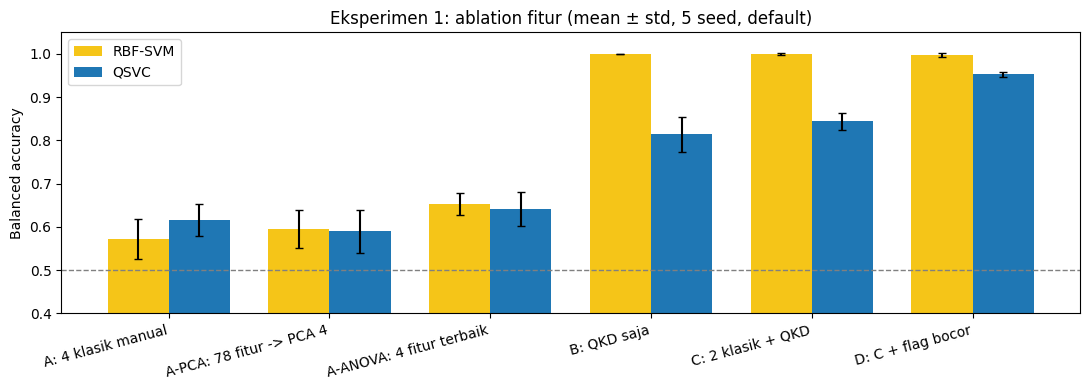

Selisih QSVC - RBF-SVM (balanced accuracy):


,set,selisih_mean,selisih_std,jelas
0,A-ANOVA: 4 fitur terbaik,-0.013,0.043,False
1,A-PCA: 78 fitur -> PCA 4,-0.005,0.041,False
2,A: 4 klasik manual,0.044,0.038,True
3,B: QKD saja,-0.186,0.041,True
4,C: 2 klasik + QKD,-0.155,0.020,True
5,D: C + flag bocor,-0.044,0.007,True


In [15]:
# Grafik balanced accuracy + selisih QSVC - RBF (apakah selisih lebih besar dari variasi antar-seed?)
agg = E1.groupby(["set", "model"])["bal_acc"].agg(["mean", "std"]).reset_index()
sets = list(SETS.values()); w = 0.38
fig, ax = plt.subplots(figsize=(11, 4))
for i, (model, color) in enumerate([("RBF-SVM", "#f5c518"), ("QSVC", "#1f77b4")]):
    d = agg[agg.model == model].set_index("set").loc[sets]
    ax.bar(np.arange(len(sets)) + (i - 0.5) * w, d["mean"], w, yerr=d["std"], label=model, color=color, capsize=3)
ax.set_xticks(np.arange(len(sets))); ax.set_xticklabels(sets, rotation=15, ha="right")
ax.axhline(0.5, ls="--", c="gray", lw=1); ax.set_ylim(0.4, 1.05); ax.set_ylabel("Balanced accuracy")
ax.set_title("Eksperimen 1: ablation fitur (mean ± std, 5 seed, default)"); ax.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "gambar_E1.png"), dpi=150); plt.show()

def paired(E, a, b, key="set"):
    # selisih a - b per seed, lalu mean dan std; 'jelas' jika |mean| > std
    out = []
    for s, g in E.groupby(key):
        x = g[g.model == a].set_index("seed")["bal_acc"]; y = g[g.model == b].set_index("seed")["bal_acc"]
        d = (x - y).dropna(); out.append(dict(**{key: s}, selisih_mean=d.mean(), selisih_std=d.std(), jelas=abs(d.mean()) > d.std()))
    return pd.DataFrame(out).round(3)
print("Selisih QSVC - RBF-SVM (balanced accuracy):"); display(paired(E1, "QSVC", "RBF-SVM"))

## 8. Eksperimen 2: tuning yang adil dan kurva belajar (RQ2 dan RQ3)
Perbandingan di Eksperimen 1 belum adil karena kedua model memakai pengaturan default. Di sini keduanya **dituning dengan anggaran yang sama (80 kombinasi)**, memakai validasi silang 3-fold **di data train saja** (test hanya disentuh sekali di akhir).

| Model | Yang dituning | Kombinasi |
|---|---|---|
| RBF-SVM | C (4 nilai) x gamma (20 nilai) | 80 |
| QSVC | feature map (4 jenis) x skala data α (5 nilai: 0,125 / 0,25 / 0,5 / 1 / 2) x C (4 nilai) | 80 |

Selain itu ada pembanding **Random Forest** yang memakai **semua 78 fitur** dengan jumlah data train yang sama (tidak dibatasi 4 qubit), supaya terlihat seberapa besar kerugian akibat pembatasan 4 fitur.
Ukuran train per kelas: 12, 24, 48, 96, 192. Eksperimen dijalankan pada tiga set fitur: **A-PCA** dan **A-ANOVA** (jujur) serta **C** (mengandung `qber`, sebagai kontras).

In [16]:
C_GRID = [0.1, 1, 10, 100]
GAMMA_GRID = [float(g) for g in np.logspace(-2, 2, 20)]      # 20 nilai
ALPHAS = [0.125, 0.25, 0.5, 1.0, 2.0]                         # skala data (bandwidth sudut) untuk quantum kernel

def tune_rbf(Xtr, ytr, Xte, seed):
    cv = StratifiedKFold(3, shuffle=True, random_state=seed)
    gs = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"), {"C": C_GRID, "gamma": GAMMA_GRID},
                      scoring="balanced_accuracy", cv=cv)
    t = time.time(); gs.fit(Xtr, ytr); fit = time.time() - t
    return gs.predict(Xte), gs.best_score_, gs.best_params_, fit

def tune_quantum(Xtr, ytr, Xte, seed):
    cv = list(StratifiedKFold(3, shuffle=True, random_state=seed).split(Xtr, ytr))
    best = (-1, None); t = time.time()
    for fm_name in FEATURE_MAPS:
        fm = FEATURE_MAPS[fm_name](Xtr.shape[1])
        for alpha in ALPHAS:
            S = q_states(fm, Xtr * alpha); K = q_kernel(S, S)            # satu matriks kernel dipakai untuk semua C dan fold
            for C in C_GRID:
                sc = []
                for a, b in cv:
                    m = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K[np.ix_(a, a)], ytr[a])
                    sc.append(balanced_accuracy_score(ytr[b], m.predict(K[np.ix_(b, a)])))
                if np.mean(sc) > best[0]: best = (np.mean(sc), (fm_name, alpha, C))
    fm_name, alpha, C = best[1]; fm = FEATURE_MAPS[fm_name](Xtr.shape[1])
    S = q_states(fm, Xtr * alpha); K = q_kernel(S, S)
    m = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K, ytr)
    p = m.predict(q_kernel(q_states(fm, Xte * alpha), S))
    return p, best[0], dict(feature_map=fm_name, alpha=alpha, C=C), time.time() - t

def run_rf_small(tr, te, seed):
    rf = RandomForestClassifier(RF_TREES * 2, random_state=seed, n_jobs=-1, class_weight="balanced").fit(tr[RAW], tr["target"])
    return rf.predict(te[RAW])

In [17]:
rows = []; t0 = time.time()
for kind in ["A-PCA", "A-ANOVA", "C"]:
    for n in SIZES:
        for seed in SEEDS:
            Xtr, ytr, Xte, yte, tr, te = prepare(kind, n, seed)
            p, cvs, par, fit = tune_rbf(Xtr, ytr, Xte, seed)
            rows.append(dict(kind=kind, n_per_kelas=n, seed=seed, model="RBF-SVM (tuned)", cv_score=cvs, params=str(par), waktu_fit=fit, **evaluate(yte, p)))
            p, cvs, par, fit = tune_quantum(Xtr, ytr, Xte, seed)
            rows.append(dict(kind=kind, n_per_kelas=n, seed=seed, model="QSVC (tuned)", cv_score=cvs, params=str(par), waktu_fit=fit, **evaluate(yte, p)))
            if kind != "A-ANOVA":          # RF memakai 78 fitur, sama untuk semua kind jujur; cukup sekali per (n, seed)
                p = run_rf_small(tr, te, seed)
                rows.append(dict(kind=kind, n_per_kelas=n, seed=seed, model="RandomForest (78 fitur)", cv_score=np.nan, params="", waktu_fit=np.nan, **evaluate(yte, p)))
    print("selesai", kind, f"({time.time() - t0:.0f} detik)")
E2 = pd.DataFrame(rows); E2.to_csv(os.path.join(OUT_DIR, "hasil_E2_tuning_kurva_belajar.csv"), index=False)

selesai A-PCA (208 detik)
selesai A-ANOVA (400 detik)
selesai C (605 detik)


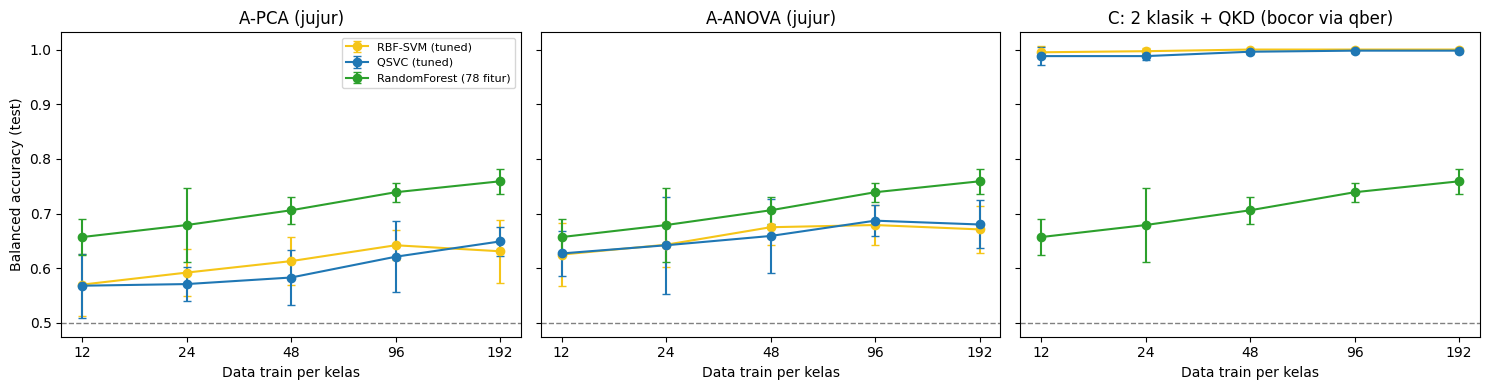

mean                                          \
model               QSVC (tuned) RBF-SVM (tuned) RandomForest (78 fitur)   
kind    n_per_kelas                                                        
A-ANOVA 12                 0.627           0.625                     NaN   
        24                 0.642           0.643                     NaN   
        48                 0.659           0.675                     NaN   
        96                 0.687           0.679                     NaN   
        192                0.680           0.671                     NaN   
A-PCA   12                 0.568           0.570                   0.657   
        24                 0.571           0.592                   0.679   
        48                 0.583           0.613                   0.706   
        96                 0.621           0.642                   0.739   
        192                0.649           0.631                   0.759   
C       12                 0.988           0.995                   0.657   
        24                 0.988           0.997                   0.679   
        48                 0.996           1.000                   0.706   
        96                 0.998           1.000                   0.739   
        192                0.998           1.000                   0.759   

                             std                                          
model               QSVC (tuned) RBF-SVM (tuned) RandomForest (78 fitur)  
kind    n_per_kelas                                                       
A-ANOVA 12                 0.041           0.057                     NaN  
        24                 0.089           0.041                     NaN  
        48                 0.067           0.032                     NaN  
        96                 0.029           0.037                     NaN  
        192                0.044           0.043                     NaN  
A-PCA   12                 0.059           0.057                   0.033  
        24                 0.032           0.043                   0.067  
        48                 0.051           0.044                   0.024  
        96                 0.065           0.028                   0.017  
        192                0.026           0.057                   0.023  
C       12                 0.016           0.011                   0.033  
        24                 0.008           0.007                   0.067  
        48                 0.004           0.000                   0.024  
        96                 0.004           0.000                   0.017  
        192                0.004           0.000                   0.023

In [18]:
# Kurva belajar: balanced accuracy vs ukuran data train
kinds = ["A-PCA", "A-ANOVA", "C"]; ttl = {"A-PCA": "A-PCA (jujur)", "A-ANOVA": "A-ANOVA (jujur)", "C": "C: 2 klasik + QKD (bocor via qber)"}
col = {"RBF-SVM (tuned)": "#f5c518", "QSVC (tuned)": "#1f77b4", "RandomForest (78 fitur)": "#2ca02c"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, kind in zip(axes, kinds):
    for model, c in col.items():
        d = E2[(E2.kind == kind) & (E2.model == model)]
        if kind == "A-ANOVA" and model.startswith("Random"): d = E2[(E2.kind == "A-PCA") & (E2.model == model)]   # RF sama
        g = d.groupby("n_per_kelas")["bal_acc"].agg(["mean", "std"])
        ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", label=model, color=c, capsize=3)
    ax.set_xscale("log", base=2); ax.set_xticks(SIZES); ax.set_xticklabels(SIZES); ax.set_title(ttl[kind]); ax.set_xlabel("Data train per kelas"); ax.axhline(0.5, ls="--", c="gray", lw=1)
axes[0].set_ylabel("Balanced accuracy (test)"); axes[0].legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "gambar_E2_kurva_belajar.png"), dpi=150); plt.show()

tab = (E2.groupby(["kind", "n_per_kelas", "model"])["bal_acc"].agg(["mean", "std"]).round(3).unstack("model"))
display(tab)

In [19]:
# Apakah QSVC (tuned) berbeda nyata dari RBF-SVM (tuned)? Selisih per seed, dibandingkan dengan variasinya
rows = []
for (kind, n), g in E2.groupby(["kind", "n_per_kelas"]):
    a = g[g.model == "QSVC (tuned)"].set_index("seed")["bal_acc"]; b = g[g.model == "RBF-SVM (tuned)"].set_index("seed")["bal_acc"]
    d = a - b; rows.append(dict(set=kind, n_per_kelas=n, selisih_mean=d.mean(), selisih_std=d.std(), QSVC_menang_di_seed=int((d > 0).sum()), dari=len(d)))
cmp_tab = pd.DataFrame(rows).round(3); cmp_tab["bukti_kuat"] = cmp_tab.selisih_mean.abs() > cmp_tab.selisih_std
display(cmp_tab)

# Konfigurasi quantum kernel yang paling sering terpilih (n=192, set A-PCA)
pilih = E2[(E2.kind == "A-PCA") & (E2.model == "QSVC (tuned)") & (E2.n_per_kelas == max(SIZES))]["params"].value_counts()
print(f"Konfigurasi QSVC terpilih (A-PCA, {max(SIZES)}/kelas):"); display(pilih)

,set,n_per_kelas,selisih_mean,selisih_std,QSVC_menang_di_seed,dari,bukti_kuat
0,A-ANOVA,12,0.002,0.041,1,5,False
1,A-ANOVA,24,-0.001,0.092,4,5,False
2,A-ANOVA,48,-0.016,0.060,3,5,False
3,A-ANOVA,96,0.008,0.021,3,5,False
4,A-ANOVA,192,0.009,0.008,4,5,True
5,A-PCA,12,-0.002,0.055,2,5,False
6,A-PCA,24,-0.021,0.027,2,5,False
7,A-PCA,48,-0.030,0.049,1,5,False
8,A-PCA,96,-0.021,0.053,2,5,False
9,A-PCA,192,0.018,0.041,3,5,False


Konfigurasi QSVC terpilih (A-PCA, 192/kelas):


,count
params,
"{'feature_map': 'ZZ reps=1 full', 'alpha': 0.5, 'C': 10}",2
"{'feature_map': 'ZZ reps=1 full', 'alpha': 0.5, 'C': 100}",1
"{'feature_map': 'ZZ reps=1 full', 'alpha': 0.125, 'C': 100}",1
"{'feature_map': 'ZZ reps=1 full', 'alpha': 0.25, 'C': 10}",1


## 9. Melihat kernel: heatmap dan *geometric difference*
**Heatmap kernel.** Matriks kernel yang baik tampak sebagai dua blok terang (data sekelas mirip) dengan area gelap di antaranya. Data diurutkan Benign dulu lalu Serangan (set A-PCA, 48 per kelas). Kita bandingkan kernel RBF klasik, quantum kernel default, dan quantum kernel dengan bandwidth lebih kecil (α = 0,25).

**Geometric difference (Huang dkk., 2021).** Ukuran seberapa berbeda geometri dua kernel. $g(K_C\|K_Q)$ kecil berarti kernel klasik $K_C$ dapat meniru quantum kernel $K_Q$, sehingga **tidak ada ruang untuk keunggulan kuantum**. $g$ besar adalah *syarat perlu* (bukan syarat cukup) agar keunggulan mungkin ada. Kita pakai versi sederhana dengan regularisasi λ.

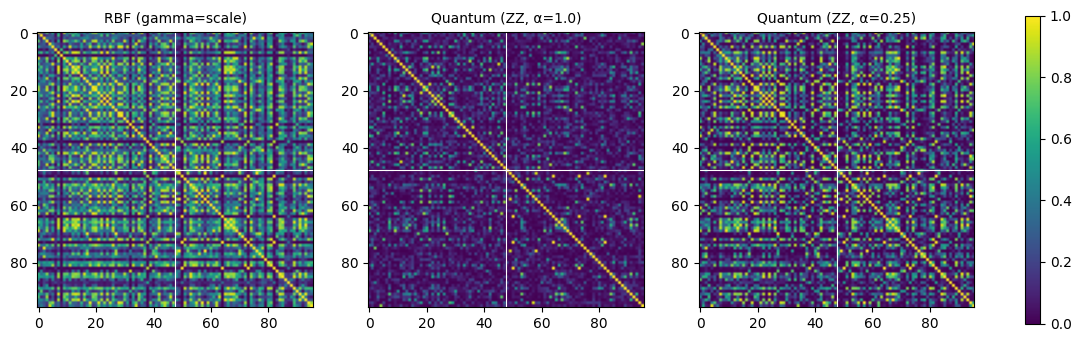

RBF (gamma=scale)            kontras = 0.023
Quantum (ZZ, α=1.0)          kontras = 0.031
Quantum (ZZ, α=0.25)         kontras = 0.026


,kernel_klasik,kernel_kuantum,g_klasik_ke_kuantum
0,RBF gamma=scale,"Quantum (ZZ, α=1.0)",27.57
1,RBF gamma=scale,"Quantum (ZZ, α=0.25)",8.89
2,RBF gamma=0.1,"Quantum (ZZ, α=1.0)",49.85
3,RBF gamma=0.1,"Quantum (ZZ, α=0.25)",35.09
4,RBF gamma=1,"Quantum (ZZ, α=1.0)",13.53
5,RBF gamma=1,"Quantum (ZZ, α=0.25)",2.39


In [20]:
from sklearn.metrics.pairwise import rbf_kernel

def sqrtm_psd(K):
    w, V = np.linalg.eigh((K + K.T) / 2); return (V * np.sqrt(np.clip(w, 0, None))) @ V.T

def geometric_difference(Kc, Kq, lam=1e-3):
    # g(Kc || Kq) = sqrt( || sqrt(Kq) (Kc + lam I)^-1 sqrt(Kq) ||_2 ), kernel dinormalisasi agar trace = n
    n = len(Kc); Kc = Kc * n / np.trace(Kc); Kq = Kq * n / np.trace(Kq)
    sq = sqrtm_psd(Kq)
    return float(np.sqrt(np.linalg.norm(sq @ np.linalg.inv(Kc + lam * np.eye(n)) @ sq, 2)))

Xtr, ytr, _, _, _, _ = prepare("A-PCA", 48, seed=0, n_test=10)
o = np.argsort(ytr, kind="stable"); Xtr, ytr = Xtr[o], ytr[o]                   # urutkan: Benign dulu, lalu Serangan
fm = FEATURE_MAPS["ZZ reps=1 linear"](4)
gamma_scale = 1 / (Xtr.shape[1] * Xtr.var())
Ks = {"RBF (gamma=scale)": rbf_kernel(Xtr, gamma=gamma_scale)}
for a in [1.0, 0.25]:
    S = q_states(fm, Xtr * a); Ks[f"Quantum (ZZ, α={a})"] = q_kernel(S, S)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a_, (t, K) in zip(ax, Ks.items()):
    im = a_.imshow(K, cmap="viridis", vmin=0, vmax=1); a_.set_title(t, fontsize=10); a_.axhline(47.5, c="w", lw=.8); a_.axvline(47.5, c="w", lw=.8)
plt.colorbar(im, ax=ax, fraction=0.02); plt.savefig(os.path.join(OUT_DIR, "gambar_heatmap_kernel.png"), dpi=150); plt.show()

# Kontras kernel: rata-rata kemiripan sekelas dikurangi antar-kelas (makin besar makin baik)
same = ytr[:, None] == ytr[None, :]
for t, K in Ks.items(): print(f"{t:28s} kontras = {K[same].mean() - K[~same].mean():.3f}")

rows = []
for gname, g in [("RBF gamma=scale", gamma_scale), ("RBF gamma=0.1", 0.1), ("RBF gamma=1", 1.0)]:
    for qname in [k for k in Ks if k.startswith("Quantum")]:
        rows.append(dict(kernel_klasik=gname, kernel_kuantum=qname, g_klasik_ke_kuantum=geometric_difference(rbf_kernel(Xtr, gamma=g), Ks[qname])))
gd = pd.DataFrame(rows).round(2); display(gd)

**Cara membaca.** Jika nilai $g$ kecil (mendekati 1 sampai beberapa), RBF dapat menyerupai quantum kernel, jadi tidak ada alasan geometris untuk berharap keunggulan kuantum. Nilai $g$ besar belum membuktikan apa pun karena keunggulan juga bergantung pada kompleksitas model dan kecocokan dengan label. Hasil ini melengkapi perbandingan akurasi dengan sudut pandang geometri kernel.

## 10. Eksperimen 3: pengaruh *shot noise* (RQ3)
Pada perangkat kuantum nyata, setiap elemen kernel diperkirakan dari sejumlah **shots**, bukan dihitung eksak. Kita tiru efeknya: tiap elemen kernel diganti hasil sampling Binomial(shots, K)/shots. Semakin sedikit shots, semakin berisik matriks kernel (lihat Bab 4, bagian 5).

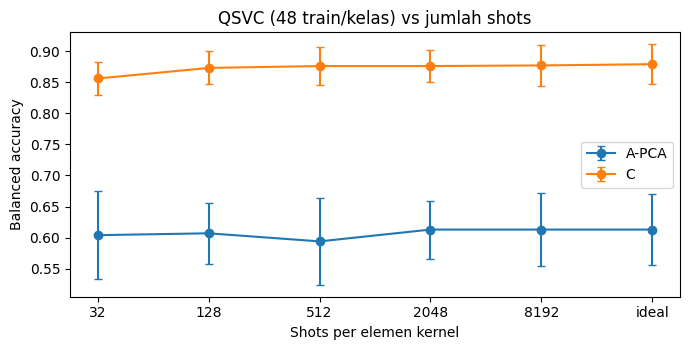

mean           std       
kind   A-PCA      C  A-PCA      C
shots                            
128    0.607  0.873  0.049  0.027
2048   0.613  0.876  0.047  0.026
32     0.604  0.856  0.070  0.026
512    0.594  0.876  0.070  0.030
8192   0.613  0.877  0.058  0.033
ideal  0.613  0.879  0.057  0.032

In [21]:
def shot_kernel(K, shots, rng, symmetric):
    Kn = rng.binomial(shots, np.clip(K, 0, 1)) / shots
    if symmetric:                                   # train: cukup segitiga atas, salin ke bawah, diagonal = 1
        Kn = np.triu(Kn, 1); Kn = Kn + Kn.T + np.eye(len(Kn))
    return Kn

SHOTS = [32, 128, 512, 2048, 8192, None] if not FAST else [128, 2048, None]            # None = ideal (tak terhingga)
rows = []
for kind in ["A-PCA", "C"]:
    for seed in SEEDS:
        Xtr, ytr, Xte, yte, _, _ = prepare(kind, 48, seed)
        fm = FEATURE_MAPS["ZZ reps=1 linear"](Xtr.shape[1]); S, St = q_states(fm, Xtr), q_states(fm, Xte)
        K, Kt = q_kernel(S, S), q_kernel(St, S); rng = np.random.default_rng(seed)
        for sh in SHOTS:
            Ka, Kb = (K, Kt) if sh is None else (shot_kernel(K, sh, rng, True), shot_kernel(Kt, sh, rng, False))
            p = SVC(kernel="precomputed", class_weight="balanced").fit(Ka, ytr).predict(Kb)
            rows.append(dict(kind=kind, shots=("ideal" if sh is None else sh), seed=seed, **evaluate(yte, p)))
E3 = pd.DataFrame(rows); E3.to_csv(os.path.join(OUT_DIR, "hasil_E3_shots.csv"), index=False)
order = [s for s in SHOTS if s is not None] + ["ideal"]
fig, ax = plt.subplots(figsize=(7, 3.6))
for kind in ["A-PCA", "C"]:
    g = E3[E3.kind == kind].assign(shots=lambda d: d.shots.astype(str)).groupby("shots")["bal_acc"].agg(["mean", "std"]).loc[[str(o) for o in order]]
    ax.errorbar(range(len(order)), g["mean"], yerr=g["std"], marker="o", capsize=3, label=kind)
ax.set_xticks(range(len(order))); ax.set_xticklabels([str(o) for o in order]); ax.set_xlabel("Shots per elemen kernel"); ax.set_ylabel("Balanced accuracy")
ax.set_title("QSVC (48 train/kelas) vs jumlah shots"); ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "gambar_E3_shots.png"), dpi=150); plt.show()
display(E3.assign(shots=E3.shots.astype(str)).groupby(["kind", "shots"])["bal_acc"].agg(["mean", "std"]).round(3).unstack("kind"))

## 11. Eksperimen 4: noise perangkat nyata (RQ5)
Hasil sebelumnya memakai simulator ideal. Perangkat IBM nyata memiliki **noise gerbang dan noise baca**. Di sini kita ukur kernel lewat sirkuit *compute-uncompute* (Bab 4): jalankan $U(x)$ lalu $U(z)^\dagger$, dan $K(x,z)$ = peluang membaca semua qubit = 0. Tiga kondisi:
1. **Ideal dengan shots** (tanpa noise gerbang).
2. **Depolarizing** pada gerbang CX dengan probabilitas p = 0,005 / 0,02 / 0,05.
3. **Fake backend IBM** (model noise dari kalibrasi perangkat nyata, `FakeManilaV2`, 5 qubit).

Kita lihat dua hal: (a) apakah $K(x,x)$ yang seharusnya = 1 menurun, (b) apakah akurasi QSVC ikut menurun. Dipakai set C (ada sinyal `qber`) karena pada set jujur akurasi sudah rendah sehingga efek noise tidak terukur.

In [22]:
if RUN_NOISE:
    try:
        import qiskit_aer, qiskit_ibm_runtime
    except Exception as e:
        print("qiskit-aer / qiskit-ibm-runtime belum terpasang, bagian noise dilewati:", e); RUN_NOISE = False
if RUN_NOISE:
    from qiskit import transpile
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error
    from qiskit_ibm_runtime.fake_provider import FakeManilaV2

    fm4 = FEATURE_MAPS["ZZ reps=1 linear"](4); SHOTS_N = 2000

    def build_circuits(A, B, sym):
        # sirkuit compute-uncompute untuk semua pasangan (train: hanya segitiga atas)
        qcs, idx = [], []
        for i, a in enumerate(A):
            for j, b in enumerate(B):
                if sym and j <= i: continue
                qc = fm4.assign_parameters(list(a)).compose(fm4.assign_parameters(list(b)).inverse()); qc.measure_all(); qcs.append(qc); idx.append((i, j))
        return qcs, idx

    def counts_to_p0(res, n): return [res.get_counts(k).get("0" * 4, 0) / SHOTS_N for k in range(n)]

    def run_setting(sim, tq_tr, idx_tr, tq_te, idx_te, tq_dg, shape_te, ntr):
        p_tr = counts_to_p0(sim.run(tq_tr, shots=SHOTS_N).result(), len(tq_tr))
        p_te = counts_to_p0(sim.run(tq_te, shots=SHOTS_N).result(), len(tq_te))
        p_dg = counts_to_p0(sim.run(tq_dg, shots=SHOTS_N).result(), len(tq_dg))
        Ktr = np.eye(ntr)
        for (i, j), v in zip(idx_tr, p_tr): Ktr[i, j] = Ktr[j, i] = v
        Kte = np.zeros(shape_te)
        for (i, j), v in zip(idx_te, p_te): Kte[i, j] = v
        return Ktr, Kte, float(np.mean(p_dg))

    BASIS = ["rz", "sx", "x", "cx"]; be = FakeManilaV2(); rows = []
    for seed in SEEDS[:NOISE_SEEDS]:
        Xtr, ytr, Xte, yte, _, _ = prepare("C", NOISE_N, seed, n_test=20)
        qtr, itr = build_circuits(Xtr, Xtr, True); qte, ite = build_circuits(Xte, Xtr, False)
        qdg = [fm4.assign_parameters(list(a)).compose(fm4.assign_parameters(list(a)).inverse()) for a in Xtr]
        for q in qdg: q.measure_all()
        S = q_states(fm4, Xtr); K_ideal, Kt_ideal = q_kernel(S, S), q_kernel(q_states(fm4, Xte), S)
        p = SVC(kernel="precomputed", class_weight="balanced").fit(K_ideal, ytr).predict(Kt_ideal)
        rows.append(dict(seed=seed, kondisi="ideal eksak", K_diag=1.0, bal_acc=balanced_accuracy_score(yte, p)))
        settings = []
        for pcx in [0.0, 0.005, 0.02, 0.05]:
            nm = NoiseModel(); nm.add_all_qubit_quantum_error(depolarizing_error(pcx, 2), ["cx"]); nm.add_all_qubit_quantum_error(depolarizing_error(pcx / 10, 1), ["sx", "x"])
            sim = AerSimulator(noise_model=nm); settings.append((f"depolarizing p={pcx}", sim, [transpile(l, sim, basis_gates=BASIS, optimization_level=0) for l in (qtr, qte, qdg)]))
        sim_f = AerSimulator.from_backend(be)
        settings.append(("fake backend Manila", sim_f, [transpile(l, be, optimization_level=0, initial_layout=[0, 1, 2, 3], seed_transpiler=seed) for l in (qtr, qte, qdg)]))
        for name, sim, (ttr, tte, tdg) in settings:
            Ktr, Kte, kd = run_setting(sim, ttr, itr, tte, ite, tdg, (len(Xte), len(Xtr)), len(Xtr))
            p = SVC(kernel="precomputed", class_weight="balanced").fit(Ktr, ytr).predict(Kte)
            same = ytr[:, None] == ytr[None, :]; off = ~np.eye(len(ytr), dtype=bool)
            rows.append(dict(seed=seed, kondisi=name, K_diag=kd, kontras=Ktr[same & off].mean() - Ktr[~same].mean(), bal_acc=balanced_accuracy_score(yte, p)))
        print("seed", seed, "selesai")
    E_noise = pd.DataFrame(rows); E_noise.to_csv(os.path.join(OUT_DIR, "hasil_E4_noise.csv"), index=False)
    ringkas_noise = E_noise.groupby("kondisi", sort=False)[["K_diag", "kontras", "bal_acc"]].agg(["mean", "std"]).round(3); display(ringkas_noise)
    print("Informasi backend:", be.name, "| jumlah qubit:", be.num_qubits)
else:
    print("RUN_NOISE = False, dilewati")

seed 0 selesai
seed 1 selesai
seed 2 selesai


K_diag        kontras        bal_acc       
                       mean    std    mean    std    mean    std
kondisi                                                         
ideal eksak           1.000  0.000     NaN    NaN   0.683  0.080
depolarizing p=0.0    1.000  0.000   0.041  0.009   0.683  0.080
depolarizing p=0.005  0.953  0.001   0.039  0.009   0.658  0.080
depolarizing p=0.02   0.822  0.002   0.033  0.007   0.650  0.090
depolarizing p=0.05   0.617  0.001   0.025  0.005   0.650  0.090
fake backend Manila   0.726  0.001   0.030  0.008   0.658  0.088

Informasi backend: fake_manila | jumlah qubit: 5


**Cara membaca.** `K_diag` adalah rata-rata $K(x,x)$ yang idealnya 1. Makin turun, makin besar sinyal yang hilang oleh noise. `kontras` adalah selisih kemiripan sekelas dan antar-kelas, yaitu "kekuatan sinyal" kernel. Akurasi bisa saja tetap bertahan pada data yang sinyalnya kuat (seperti set C) meskipun nilai kernel sudah merosot, karena SVM hanya membutuhkan urutan kemiripan yang masih benar. Pada sirkuit yang lebih dalam atau lebih lebar (lihat Bab 4, bagian 7 dan 13) penurunan ini jauh lebih merusak.

## 12. Eksperimen 5: VQC (jalur lanjut)
*Variational Quantum Classifier* memakai sirkuit berparameter (ZZ feature map + ansatz `RealAmplitudes`) dan optimizer klasik COBYLA. Risikonya: barren plateau, minimum lokal, dan waktu training. Perbandingan memakai set A-PCA dan split yang sama dengan model lain.

In [23]:
if RUN_VQC:
    from qiskit.circuit.library import real_amplitudes
    from qiskit_machine_learning.algorithms import VQC
    from qiskit_machine_learning.optimizers import COBYLA
    rows = []
    for n in [24, 48]:
        for seed in SEEDS:
            Xtr, ytr, Xte, yte, _, _ = prepare("A-PCA", n, seed)
            np.random.seed(seed)
            t = time.time()
            vqc = VQC(feature_map=zz_feature_map(4, reps=1, entanglement="linear"), ansatz=real_amplitudes(4, reps=1),
                      optimizer=COBYLA(maxiter=VQC_ITERS))
            vqc.fit(Xtr, ytr); fit = time.time() - t
            rows.append(dict(n_per_kelas=n, seed=seed, model="VQC", waktu_fit=fit, **evaluate(yte, vqc.predict(Xte))))
            for name, fn in [("RBF-SVM (default)", run_rbf), ("QSVC (default)", run_qk)]:
                p, f, _ = fn(Xtr, ytr, Xte); rows.append(dict(n_per_kelas=n, seed=seed, model=name, waktu_fit=f, **evaluate(yte, p)))
    E4 = pd.DataFrame(rows); E4.to_csv(os.path.join(OUT_DIR, "hasil_E4_vqc.csv"), index=False)
    display(E4.groupby(["n_per_kelas", "model"])[["bal_acc", "macro_f1", "recall_serangan", "fpr", "waktu_fit"]].agg(["mean", "std"]).round(3))
else:
    print("RUN_VQC = False, dilewati")

bal_acc        macro_f1        recall_serangan  \
                                 mean    std     mean    std            mean   
n_per_kelas model                                                              
24          QSVC (default)      0.590  0.050    0.588  0.050           0.614   
            RBF-SVM (default)   0.595  0.044    0.585  0.045           0.498   
            VQC                 0.569  0.035    0.567  0.036           0.526   
48          QSVC (default)      0.613  0.057    0.612  0.056           0.632   
            RBF-SVM (default)   0.605  0.045    0.601  0.042           0.526   
            VQC                 0.538  0.014    0.532  0.018           0.500   

                                        fpr        waktu_fit         
                                 std   mean    std      mean    std  
n_per_kelas model                                                    
24          QSVC (default)     0.108  0.434  0.044     0.055  0.013  
            RBF-SVM (default)  0.153  0.308  0.139     0.002  0.000  
            VQC                0.080  0.388  0.063    18.807  0.702  
48          QSVC (default)     0.110  0.406  0.043     0.101  0.008  
            RBF-SVM (default)  0.043  0.316  0.102     0.002  0.000  
            VQC                0.125  0.424  0.105    34.847  0.931

## 13. Eksperimen 6: pembanding klasik yang kuat dan serangan mana yang sulit (RQ4)
Sampai sini kita memakai subset kecil dan seimbang. Untuk melihat kondisi yang lebih realistis, kita latih **Random Forest** pada 50.000 baris dan uji pada **seluruh test pool dengan distribusi alami** (76% benign). Tiga skenario fitur:
1. **Jujur:** 78 fitur jaringan saja.
2. **+ QKD:** ditambah `qber` dan `sifted_key_rate`.
3. **+ QKD + flag bocor.**

Lalu kita lihat **recall per jenis serangan** pada skenario jujur, untuk mengetahui serangan mana yang sulit dideteksi.

In [24]:
sub = train_pool.sample(RF_SUB, random_state=0)
SCEN = {"1. Jujur (78 fitur jaringan)": RAW, "2. + QKD": RAW + QKD, "3. + QKD + flag bocor": RAW + QKD + LEAK}
rows, preds = [], {}
for name, feats in SCEN.items():
    t = time.time()
    rf = RandomForestClassifier(RF_TREES, random_state=0, n_jobs=-1, class_weight="balanced").fit(sub[feats], sub["target"])
    p = rf.predict(test_pool[feats]); preds[name] = p
    rows.append(dict(skenario=name, waktu_fit=time.time() - t, **evaluate(test_pool["target"].values, p)))
E5 = pd.DataFrame(rows); E5.to_csv(os.path.join(OUT_DIR, "hasil_E5_rf_skala_penuh.csv"), index=False)
display(E5.round(3))

,skenario,waktu_fit,bal_acc,macro_f1,recall_serangan,fpr
0,1. Jujur (78 fitur jaringan),46.702,0.817,0.858,0.638,0.004
1,2. + QKD,25.659,1.000,1.000,1.000,0.000
2,3. + QKD + flag bocor,18.233,1.000,1.000,1.000,0.000


,jumlah_test,terdeteksi,keluarga
label,,,
SQL Injection,10.0,0.000,Web attack
Infilteration,3138.0,0.076,Infiltration
Brute Force -Web,73.0,0.151,Web attack
Brute Force -XSS,49.0,0.327,Web attack
DoS attacks-GoldenEye,120.0,0.425,DoS
Bot-Aggressive,2028.0,0.706,Bot
DoS attacks-Slowloris,475.0,0.804,DoS
Bot-Stealth,1994.0,0.849,Bot
DoS attacks-Hulk,39.0,0.949,DoS


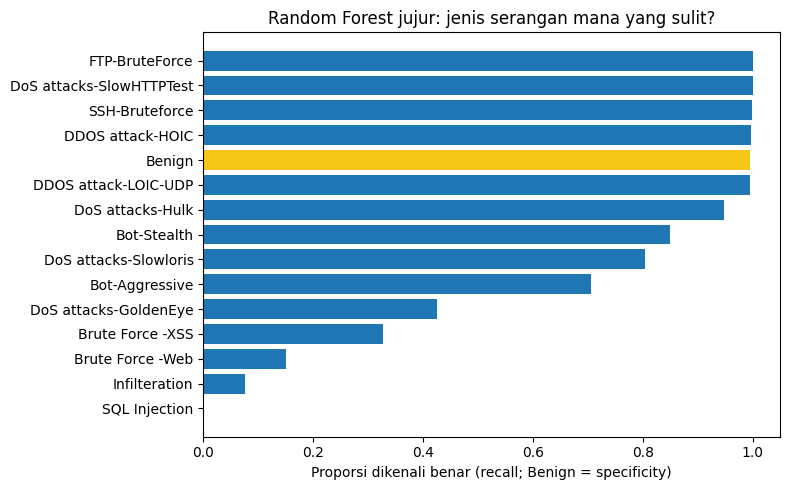

In [25]:
# Recall per jenis serangan (skenario jujur). Benign dilaporkan sebagai specificity.
tp = test_pool.assign(pred=preds["1. Jujur (78 fitur jaringan)"])
per = tp.groupby("label").apply(lambda g: pd.Series({"jumlah_test": len(g),
        "terdeteksi": (g.pred == (0 if g.name == "Benign" else 1)).mean()})).sort_values("terdeteksi")
per["keluarga"] = per.index.map(FAMILY)
display(per.round(3))
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#f5c518" if i == "Benign" else "#1f77b4" for i in per.index]
ax.barh(per.index, per["terdeteksi"], color=colors); ax.set_xlabel("Proporsi dikenali benar (recall; Benign = specificity)")
ax.set_title("Random Forest jujur: jenis serangan mana yang sulit?"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "gambar_E5_recall_per_serangan.png"), dpi=150); plt.show()

## 14. Eksperimen 7: split waktu (RQ4)
Split acak membuat train dan test berisi pola yang sangat mirip dari hari yang sama. Skenario yang lebih realistis: **belajar dari masa lalu, diuji pada masa depan**. Hanya berkas *base* yang menyimpan `timestamp`. Kita bandingkan split acak vs split waktu (70% awal untuk train, 30% akhir untuk test) memakai Random Forest dan fitur yang sama.

Train: 2018-02-14 01:00:00 s/d 2018-02-28 11:04:27 | Test: 2018-02-28 11:04:28 s/d 2018-03-02 12:59:59
Proporsi serangan  train: 0.147 | test: 0.456
Jenis serangan hanya ada di test: ['Bot']


,split,fitur,bal_acc,macro_f1,recall_serangan,fpr
0,split acak,jujur (78 fitur),0.817,0.857,0.640,0.006
1,split acak,+ QKD,1.000,1.000,1.000,0.000
2,split waktu,jujur (78 fitur),0.507,0.368,0.015,0.001
3,split waktu,+ QKD,1.000,1.000,1.000,0.000


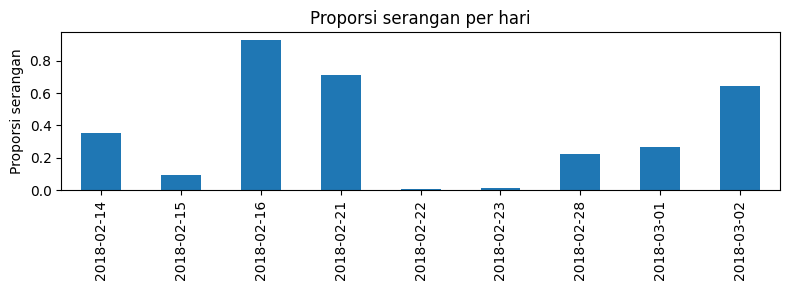

In [26]:
if RUN_TIME_SPLIT and os.path.exists(BASE):
    b = pd.read_parquet(BASE, columns=RAW + QKD + ["label"]).replace([np.inf, -np.inf], np.nan).dropna().sort_index()
    b["target"] = (b["label"] != "Benign").astype(int)
    cut = int(len(b) * 0.7); trb, teb = b.iloc[:cut], b.iloc[cut:]
    print("Train:", trb.index.min(), "s/d", trb.index.max(), "| Test:", teb.index.min(), "s/d", teb.index.max())
    print("Proporsi serangan  train:", round(trb.target.mean(), 3), "| test:", round(teb.target.mean(), 3))
    print("Jenis serangan hanya ada di test:", sorted(set(teb.label) - set(trb.label)))
    rs_tr, rs_te = train_test_split(b, test_size=0.3, stratify=b["target"], random_state=0)
    rows = []
    for split, (a, c) in {"split acak": (rs_tr, rs_te), "split waktu": (trb, teb)}.items():
        for name, feats in {"jujur (78 fitur)": RAW, "+ QKD": RAW + QKD}.items():
            s = a.sample(min(RF_SUB, len(a)), random_state=0)
            rf = RandomForestClassifier(RF_TREES, random_state=0, n_jobs=-1, class_weight="balanced").fit(s[feats], s["target"])
            rows.append(dict(split=split, fitur=name, **evaluate(c["target"].values, rf.predict(c[feats]))))
    E6 = pd.DataFrame(rows); E6.to_csv(os.path.join(OUT_DIR, "hasil_E6_split_waktu.csv"), index=False); display(E6.round(3))
    harian = b.groupby(b.index.date)["target"].mean()
    ax = harian.plot(kind="bar", figsize=(8, 3), color="#1f77b4"); ax.set_ylabel("Proporsi serangan"); ax.set_title("Proporsi serangan per hari"); plt.tight_layout(); plt.show()
else:
    print("Dilewati: set RUN_TIME_SPLIT=True dan pastikan berkas base ada di", BASE)

## 15. Eksperimen 8: dataset kedua, NSL-KDD (RQ4)
Kelemahan terbesar HQC-2026 adalah fitur QKD yang bocor, sehingga hanya fitur jaringan yang jujur dan skornya rendah. Untuk menguji apakah kesimpulan bergantung pada dataset ini, kita ulangi perbandingan RBF-SVM vs QSVC pada **NSL-KDD**, benchmark IDS klasik yang **tidak memiliki fitur QKD**. NSL-KDD dibagi resmi menjadi `KDDTrain+` (125.973 baris) dan `KDDTest+` (22.544 baris, memuat jenis serangan baru yang tidak ada di train), sehingga tesnya lebih menantang dan lebih realistis.

Pipeline sama persis: sampel seimbang kecil, fitur dikecilkan jadi 4 (PCA atau ANOVA, dipelajari dari train), skala sudut [0, π], tuning adil 80 kombinasi, 5 seed, kurva belajar. Berkas diunduh otomatis dari GitHub; jika gagal (tidak ada internet), unggah `KDDTrain+.txt` dan `KDDTest+.txt` ke folder `DATA_DIR`.

In [27]:
if RUN_NSLKDD:
    import urllib.request
    from sklearn.preprocessing import OneHotEncoder
    NSL = {"KDDTrain+.txt": "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
           "KDDTest+.txt":  "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt"}
    NSL_PATH = {}
    for fn, url in NSL.items():
        for folder in [DATA_DIR, OUT_DIR]:
            if os.path.exists(os.path.join(folder, fn)): NSL_PATH[fn] = os.path.join(folder, fn); break
        else:
            for folder in [DATA_DIR, OUT_DIR]:
                try:
                    urllib.request.urlretrieve(url, os.path.join(folder, fn)); NSL_PATH[fn] = os.path.join(folder, fn); break
                except Exception as e: last = e
    HAVE_NSL = len(NSL_PATH) == 2
    print("NSL-KDD tersedia:", HAVE_NSL, NSL_PATH if HAVE_NSL else "-> unggah manual KDDTrain+.txt dan KDDTest+.txt ke DATA_DIR")
else:
    HAVE_NSL = False

NSL-KDD tersedia: True {'KDDTrain+.txt': '/content/drive/MyDrive/Quantum/KDDTrain+.txt', 'KDDTest+.txt': '/content/drive/MyDrive/Quantum/KDDTest+.txt'}


In [28]:
if HAVE_NSL:
    NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot","num_failed_logins",
        "logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations","num_shells","num_access_files","num_outbound_cmds",
        "is_host_login","is_guest_login","count","srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate",
        "diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
        "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate",
        "dst_host_srv_rerror_rate","label","difficulty"]
    nsl_tr = pd.read_csv(NSL_PATH["KDDTrain+.txt"], header=None, names=NSL_COLS); nsl_te = pd.read_csv(NSL_PATH["KDDTest+.txt"], header=None, names=NSL_COLS)
    for d in (nsl_tr, nsl_te): d["target"] = (d["label"] != "normal").astype(int)
    CAT = ["protocol_type", "service", "flag"]; NUM = [c for c in NSL_COLS[:41] if c not in CAT]
    print("Train:", nsl_tr.shape, "| serangan", round(nsl_tr.target.mean(), 3), "| Test:", nsl_te.shape, "| serangan", round(nsl_te.target.mean(), 3))
    print("Jenis serangan hanya ada di test (tidak ada di train):", len(set(nsl_te.label) - set(nsl_tr.label)), "jenis")

    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(nsl_tr[CAT])
    nsl_matrix = lambda d: np.hstack([slog(d[NUM].values.astype(float)), ohe.transform(d[CAT])])
    fit_n = nsl_tr.sample(20000, random_state=0)
    sc_n = StandardScaler().fit(nsl_matrix(fit_n)); pca_n = PCA(4, random_state=0).fit(sc_n.transform(nsl_matrix(fit_n)))
    sel_n = SelectKBest(f_classif, k=4).fit(slog(fit_n[NUM].values.astype(float)), fit_n["target"]); NSL_ANOVA = [NUM[i] for i in sel_n.get_support(indices=True)]
    print("4 fitur ANOVA terbaik NSL-KDD:", NSL_ANOVA)

    def nsl_features(kind, d):
        if kind == "PCA4":   return pca_n.transform(sc_n.transform(nsl_matrix(d)))
        if kind == "ANOVA4": return slog(d[NSL_ANOVA].values.astype(float))
    def prepare_nsl(kind, n, seed, n_test=N_TEST):
        tr = sample_each(nsl_tr, n, seed); te = sample_each(nsl_te, n_test, seed + 1000)
        Xtr, Xte = nsl_features(kind, tr), nsl_features(kind, te); mm = MinMaxScaler((0, np.pi)).fit(Xtr)
        return mm.transform(Xtr), tr["target"].values, mm.transform(Xte), te["target"].values, tr, te

Train: (125973, 44) | serangan 0.465 | Test: (22544, 44) | serangan 0.569
Jenis serangan hanya ada di test (tidak ada di train): 17 jenis
4 fitur ANOVA terbaik NSL-KDD: ['src_bytes', 'dst_bytes', 'same_srv_rate', 'dst_host_same_srv_rate']


selesai PCA4 (200 detik)
selesai ANOVA4 (381 detik)


mean                                             \
model              QSVC (tuned) RBF-SVM (tuned) RandomForest (semua fitur)   
kind   n_per_kelas                                                           
ANOVA4 12                 0.750           0.741                        NaN   
       24                 0.772           0.752                        NaN   
       48                 0.778           0.798                        NaN   
       96                 0.786           0.782                        NaN   
       192                0.778           0.795                        NaN   
PCA4   12                 0.750           0.798                      0.754   
       24                 0.808           0.800                      0.785   
       48                 0.792           0.770                      0.781   
       96                 0.788           0.789                      0.788   
       192                0.801           0.785                      0.794   

                            std                                             
model              QSVC (tuned) RBF-SVM (tuned) RandomForest (semua fitur)  
kind   n_per_kelas                                                          
ANOVA4 12                 0.043           0.014                        NaN  
       24                 0.035           0.037                        NaN  
       48                 0.019           0.033                        NaN  
       96                 0.012           0.018                        NaN  
       192                0.007           0.018                        NaN  
PCA4   12                 0.088           0.030                      0.026  
       24                 0.033           0.023                      0.015  
       48                 0.029           0.021                      0.029  
       96                 0.016           0.013                      0.017  
       192                0.023           0.011                      0.009

Random Forest skala penuh pada KDDTest+: {'bal_acc': np.float64(0.786), 'macro_f1': 0.759, 'recall_serangan': 0.6, 'fpr': np.float64(0.027)}


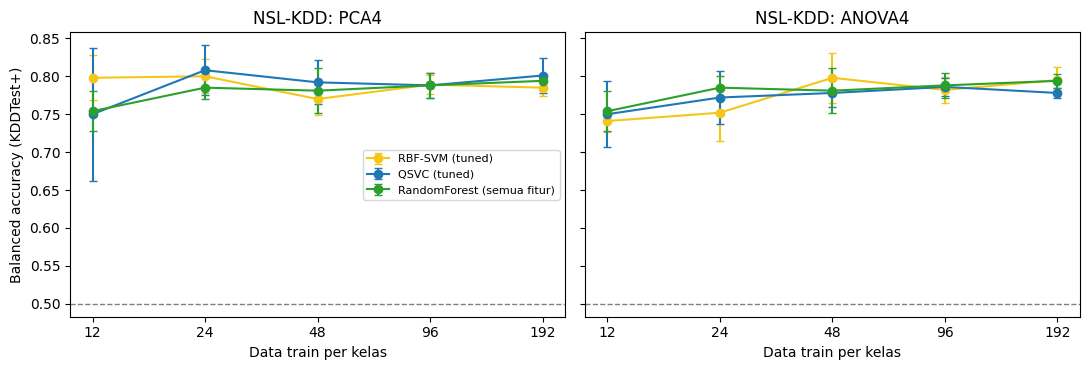

In [29]:
if HAVE_NSL:
    rows = []; t0 = time.time()
    for kind in ["PCA4", "ANOVA4"]:
        for n in SIZES:
            for seed in SEEDS:
                Xtr, ytr, Xte, yte, tr, te = prepare_nsl(kind, n, seed)
                p, cvs, par, fit = tune_rbf(Xtr, ytr, Xte, seed); rows.append(dict(kind=kind, n_per_kelas=n, seed=seed, model="RBF-SVM (tuned)", params=str(par), **evaluate(yte, p)))
                p, cvs, par, fit = tune_quantum(Xtr, ytr, Xte, seed); rows.append(dict(kind=kind, n_per_kelas=n, seed=seed, model="QSVC (tuned)", params=str(par), **evaluate(yte, p)))
                if kind == "PCA4":
                    rf = RandomForestClassifier(RF_TREES * 2, random_state=seed, n_jobs=-1, class_weight="balanced").fit(nsl_matrix(tr), tr["target"])
                    rows.append(dict(kind=kind, n_per_kelas=n, seed=seed, model="RandomForest (semua fitur)", params="", **evaluate(yte, rf.predict(nsl_matrix(te)))))
        print("selesai", kind, f"({time.time() - t0:.0f} detik)")
    E8 = pd.DataFrame(rows); E8.to_csv(os.path.join(OUT_DIR, "hasil_E8_nslkdd.csv"), index=False)
    display(E8.groupby(["kind", "n_per_kelas", "model"])["bal_acc"].agg(["mean", "std"]).round(3).unstack("model"))

    # Pembanding skala penuh pada KDDTest+ (distribusi alami)
    big = nsl_tr.sample(min(RF_SUB, len(nsl_tr)), random_state=0)
    rf = RandomForestClassifier(RF_TREES, random_state=0, n_jobs=-1, class_weight="balanced").fit(nsl_matrix(big), big["target"])
    ref_nsl = evaluate(nsl_te["target"].values, rf.predict(nsl_matrix(nsl_te))); print("Random Forest skala penuh pada KDDTest+:", {k: round(v, 3) for k, v in ref_nsl.items()})

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, kind in zip(axes, ["PCA4", "ANOVA4"]):
        for model, c in [("RBF-SVM (tuned)", "#f5c518"), ("QSVC (tuned)", "#1f77b4"), ("RandomForest (semua fitur)", "#2ca02c")]:
            d = E8[(E8.kind == ("PCA4" if model.startswith("Random") else kind)) & (E8.model == model)]
            g = d.groupby("n_per_kelas")["bal_acc"].agg(["mean", "std"]); ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, label=model, color=c)
        ax.set_xscale("log", base=2); ax.set_xticks(SIZES); ax.set_xticklabels(SIZES); ax.set_title("NSL-KDD: " + kind); ax.set_xlabel("Data train per kelas"); ax.axhline(0.5, ls="--", c="gray", lw=1)
    axes[0].set_ylabel("Balanced accuracy (KDDTest+)"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "gambar_E8_nslkdd.png"), dpi=150); plt.show()

## 16. Opsional: satu elemen kernel di IBM Quantum (perangkat nyata)
Mengikuti Bab 4: satu elemen kernel dihitung dengan rangkaian *unitary overlap*, lalu peluang semua qubit terbaca nol ≈ $K(x,z)$. Kita bandingkan nilai dari **perangkat nyata** dengan nilai **ideal** simulator. Bagian ini mati secara default (`RUN_IBM = False`) karena butuh akun IBM Quantum dan antrean QPU. Kode mengikuti contoh Bab 4 dan **tidak diuji di sini** tanpa akses perangkat. Jika tidak dijalankan, tuliskan sebagai pekerjaan lanjutan.

In [30]:
if RUN_IBM:
    # !pip install -q qiskit-ibm-runtime   (jalankan di sel terpisah, lalu restart)
    from qiskit.circuit.library import unitary_overlap
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

    Xtr, ytr, _, _, _, _ = prepare("A-PCA", 12, seed=0)
    x0, x1 = Xtr[ytr == 0][0], Xtr[ytr == 1][0]                  # satu data benign dan satu serangan
    fm = z_feature_map(4, reps=2)                                  # feature map dangkal agar muat di QPU
    K_ideal = float(q_kernel(q_states(fm, x0[None]), q_states(fm, x1[None]))[0, 0])

    ov = unitary_overlap(fm.assign_parameters(x0), fm.assign_parameters(x1)); ov.measure_all()
    service = QiskitRuntimeService()                               # butuh token IBM Quantum yang tersimpan
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=4)
    ov_t = generate_preset_pass_manager(optimization_level=3, backend=backend).run(ov)
    print("Backend:", backend.name, "| depth:", ov_t.depth(), "| two-qubit depth:", ov_t.depth(lambda i: len(i.qubits) > 1))
    shots = 4096
    counts = Sampler(mode=backend).run([ov_t], shots=shots).result()[0].data.meas.get_int_counts()
    K_hw = counts.get(0, 0) / shots
    print(f"K ideal (simulator) = {K_ideal:.4f} | K perangkat nyata = {K_hw:.4f} | selisih = {abs(K_ideal - K_hw):.4f}")
else:
    print("RUN_IBM = False, dilewati (opsional)")

RUN_IBM = False, dilewati (opsional)


## 17. Ringkasan hasil dan kesimpulan

In [31]:
# Ringkasan satu tabel untuk laporan/slide
ring = []
a = E1.groupby(["kind", "model"])["bal_acc"].mean().unstack()
for k in ["A", "A-PCA", "A-ANOVA", "B", "C", "D"]:
    ring.append({"Eksperimen": "E1 default, 24/kelas", "Set fitur": SETS[k], "RBF-SVM": a.loc[k, "RBF-SVM"], "QSVC": a.loc[k, "QSVC"]})
b2 = E2[E2.n_per_kelas == max(SIZES)].groupby(["kind", "model"])["bal_acc"].mean().unstack()
for k in ["A-PCA", "A-ANOVA", "C"]:
    ring.append({"Eksperimen": f"E2 tuned, {max(SIZES)}/kelas", "Set fitur": SETS[k], "RBF-SVM": b2.loc[k, "RBF-SVM (tuned)"], "QSVC": b2.loc[k, "QSVC (tuned)"],
                 "RandomForest 78 fitur": b2.loc["A-PCA", "RandomForest (78 fitur)"]})
display(pd.DataFrame(ring).round(3))
print("Semua CSV dan gambar tersimpan di:", OUT_DIR)

,Eksperimen,Set fitur,RBF-SVM,QSVC,RandomForest 78 fitur
0,"E1 default, 24/kelas",A: 4 klasik manual,0.572,0.616,NaN
1,"E1 default, 24/kelas",A-PCA: 78 fitur -> PCA 4,0.595,0.590,NaN
2,"E1 default, 24/kelas",A-ANOVA: 4 fitur terbaik,0.654,0.641,NaN
3,"E1 default, 24/kelas",B: QKD saja,1.000,0.814,NaN
4,"E1 default, 24/kelas",C: 2 klasik + QKD,0.999,0.844,NaN
5,"E1 default, 24/kelas",D: C + flag bocor,0.997,0.953,NaN
6,"E2 tuned, 192/kelas",A-PCA: 78 fitur -> PCA 4,0.631,0.649,0.759
7,"E2 tuned, 192/kelas",A-ANOVA: 4 fitur terbaik,0.671,0.680,0.759
8,"E2 tuned, 192/kelas",C: 2 klasik + QKD,1.000,0.998,0.759


Semua CSV dan gambar tersimpan di: /content/drive/MyDrive/Quantum


In [32]:
# Ringkasan otomatis angka-angka kunci (dihitung dari hasil di atas, jadi selalu cocok dengan notebook yang Anda jalankan)
def m(df_, **flt):
    d = df_
    for k, v in flt.items(): d = d[d[k] == v]
    return d["bal_acc"].mean(), d["bal_acc"].std()
print("=== E1 (default, 24/kelas; balanced accuracy mean ± std) ===")
for k, lab in SETS.items():
    r, q = m(E1, kind=k, model="RBF-SVM"), m(E1, kind=k, model="QSVC"); print(f"{lab:28s} RBF {r[0]:.3f}±{r[1]:.3f} | QSVC {q[0]:.3f}±{q[1]:.3f}")
nmax = max(SIZES)
print(f"\n=== E2 (tuned, {nmax}/kelas) ===")
for k in ["A-PCA", "A-ANOVA", "C"]:
    d = E2[(E2.kind == k) & (E2.n_per_kelas == nmax)]
    print(f"{k:8s} RBF {m(d, model='RBF-SVM (tuned)')[0]:.3f} | QSVC {m(d, model='QSVC (tuned)')[0]:.3f} | RF-78fitur {m(E2[(E2.kind=='A-PCA')&(E2.n_per_kelas==nmax)], model='RandomForest (78 fitur)')[0]:.3f}")
print("\n=== E6 (Random Forest skala penuh, distribusi alami) ===")
display(E5[["skenario", "bal_acc", "macro_f1", "recall_serangan", "fpr"]].round(3))
if "E6" in globals(): print("\n=== E7 split waktu ==="); display(E6[["split", "fitur", "bal_acc", "recall_serangan", "fpr"]].round(3))
if "E8" in globals():
    print(f"\n=== NSL-KDD ({nmax}/kelas) ===")
    for k in ["PCA4", "ANOVA4"]:
        d = E8[(E8.kind == k) & (E8.n_per_kelas == nmax)]; print(f"{k:7s} RBF {m(d, model='RBF-SVM (tuned)')[0]:.3f} | QSVC {m(d, model='QSVC (tuned)')[0]:.3f}")
if "E_noise" in globals(): print("\n=== Noise ==="); display(ringkas_noise)

=== E1 (default, 24/kelas; balanced accuracy mean ± std) ===
A: 4 klasik manual           RBF 0.572±0.046 | QSVC 0.616±0.038
A-PCA: 78 fitur -> PCA 4     RBF 0.595±0.044 | QSVC 0.590±0.050
A-ANOVA: 4 fitur terbaik     RBF 0.654±0.026 | QSVC 0.641±0.039
B: QKD saja                  RBF 1.000±0.000 | QSVC 0.814±0.041
C: 2 klasik + QKD            RBF 0.999±0.002 | QSVC 0.844±0.019
D: C + flag bocor            RBF 0.997±0.004 | QSVC 0.953±0.006

=== E2 (tuned, 192/kelas) ===
A-PCA    RBF 0.631 | QSVC 0.649 | RF-78fitur 0.759
A-ANOVA  RBF 0.671 | QSVC 0.680 | RF-78fitur 0.759
C        RBF 1.000 | QSVC 0.998 | RF-78fitur 0.759

=== E6 (Random Forest skala penuh, distribusi alami) ===


,skenario,bal_acc,macro_f1,recall_serangan,fpr
0,1. Jujur (78 fitur jaringan),0.817,0.858,0.638,0.004
1,2. + QKD,1.000,1.000,1.000,0.000
2,3. + QKD + flag bocor,1.000,1.000,1.000,0.000



=== E7 split waktu ===


,split,fitur,bal_acc,recall_serangan,fpr
0,split acak,jujur (78 fitur),0.817,0.640,0.006
1,split acak,+ QKD,1.000,1.000,0.000
2,split waktu,jujur (78 fitur),0.507,0.015,0.001
3,split waktu,+ QKD,1.000,1.000,0.000



=== NSL-KDD (192/kelas) ===
PCA4    RBF 0.785 | QSVC 0.801
ANOVA4  RBF 0.795 | QSVC 0.778

=== Noise ===


K_diag        kontras        bal_acc       
                       mean    std    mean    std    mean    std
kondisi                                                         
ideal eksak           1.000  0.000     NaN    NaN   0.683  0.080
depolarizing p=0.0    1.000  0.000   0.041  0.009   0.683  0.080
depolarizing p=0.005  0.953  0.001   0.039  0.009   0.658  0.080
depolarizing p=0.02   0.822  0.002   0.033  0.007   0.650  0.090
depolarizing p=0.05   0.617  0.001   0.025  0.005   0.650  0.090
fake backend Manila   0.726  0.001   0.030  0.008   0.658  0.088

## Kesimpulan
Angka di bawah berasal dari eksekusi lengkap notebook ini (5 seed, test 100 per kelas, simulator ideal). Seed dipatok, jadi hasil di Colab Anda seharusnya sama atau sangat mirip. **Cocokkan dengan sel "Ringkasan otomatis" di atas** sebelum menyalin angka ke slide.

**RQ1: apakah fitur QKD menambah kemampuan deteksi?** Tidak. `qber` memiliki AUC 1,000 (fitur jaringan terbaik hanya 0,71), rentang benign (maks 0,032) dan serangan (min 0,120) tidak tumpang tindih, dan aturan "qber > 0,05" benar pada 100% data. `sifted_key_rate` tidak membawa sinyal (AUC 0,50). Skor ≈1,00 pada set B, C, D adalah *target leakage*, bukan kemampuan mendeteksi serangan.

**RQ5: asal fisik QBER.** Simulasi BB84 kami menghasilkan QBER ≈0,01 tanpa penyadap dan ≈0,25 jika semua qubit disadap, sesuai teori. QBER serangan di dataset (0,18) setara dengan Eve yang menyadap ±68% qubit. QBER adalah properti kanal kuantum, bukan properti aliran jaringan, jadi keterpisahan sempurnanya hampir pasti hasil pembangkitan dari label, bukan hasil pengukuran dari trafik.

**RQ2: QSVC vs RBF-SVM pada fitur jujur (tanpa qber), setelah tuning adil 80 kombinasi.** Setara. Pada 192 data per kelas: A-PCA 0,649 (QSVC) vs 0,631 (RBF), A-ANOVA 0,680 vs 0,671. Selisihnya (maks ±0,03) selalu lebih kecil atau sama dengan variasi antar-seed pada semua ukuran data. Kurva belajar naik pelan untuk kedua model dan tidak menunjukkan QSVC menyusul atau menyalip. Yang jelas terlihat adalah **pembatasan 4 fitur**, bukan jenis kernelnya: Random Forest dengan 78 fitur mencapai 0,759 pada data train yang sama.

**Quantum kernel default tampak kalah hanya karena konfigurasi.** Pada set ber-`qber`, QSVC default 0,81 sampai 0,95 sedangkan RBF 1,00. Setelah dituning (bandwidth sudut kecil α = 0,125, C kecil), QSVC mencapai 0,998. Tanpa tuning, perbandingan "kuantum vs klasik" bisa menyesatkan.

**RQ3: perilaku quantum kernel.** (a) *Shot noise* hampir tidak berpengaruh pada 48 data per kelas sampai 32 shots untuk set jujur, dan hanya menurunkan set C sedikit (0,856 pada 32 shots vs 0,879 ideal). (b) *Geometric difference* antara RBF dan quantum kernel besar (2,4 sampai 50), jadi geometri kernelnya memang berbeda, tetapi perbedaan itu **tidak** menghasilkan akurasi lebih baik; nilai g besar hanyalah syarat perlu, bukan bukti keunggulan. (c) VQC lebih lemah dan mendekati acak (0,58 pada 24 dan 48 data per kelas, vs 0,59 sampai 0,61 untuk QSVC/RBF default), dengan satu konfigurasi dan 100 iterasi COBYLA. (d) Biaya: kernel ZZ linear 4 qubit membutuhkan 12 gerbang CX per sirkuit overlap, dan jumlah sirkuit tumbuh sekitar n² (12.240 sirkuit untuk 96 data train dan 200 data test).

**Noise perangkat (RQ5).** Nilai kernel $K(x,x)$ (ideal 1,0) turun menjadi 0,95; 0,82; dan 0,62 pada noise gerbang 0,005; 0,02; dan 0,05, dan 0,73 pada model noise `FakeManilaV2`. Kontras kernel (selisih kemiripan sekelas vs antar-kelas) ikut melemah. Akurasi pada eksperimen kecil ini hanya turun dari 0,68 ke ±0,65, masih dalam variasi antar-seed, sehingga efek noise terhadap akurasi **belum terbukti pada skala ini**, sedangkan efek terhadap nilai kernel jelas. Pada sirkuit yang lebih dalam dan lebar penurunan ini akan jauh lebih merusak (Bab 4).

**RQ4: bertahan pada pembanding kuat, split waktu, dan dataset lain?**
- *Random Forest 78 fitur (skala penuh, distribusi alami):* balanced accuracy 0,82, recall serangan 0,64, FPR 0,004. Serangan yang sulit: SQL Injection (0%), Infilteration (8%), Brute Force Web (15%), Brute Force XSS (35%).
- *Split waktu (berkas base):* fitur jaringan jujur turun dari balanced accuracy 0,82 (split acak) menjadi **0,51** dengan recall serangan hanya **1,4%**. Perhatikan bahwa pada split ini jenis serangan Bot hanya muncul di test, jadi ini uji ketahanan terhadap pergeseran distribusi, bukan perbandingan setara. Sebaliknya, dengan `qber` skor tetap 1,00, lagi-lagi bukti kebocoran. Split acak terlalu optimistis.
- *NSL-KDD (tanpa QKD, test resmi dengan 17 jenis serangan baru):* RBF-SVM, QSVC, dan Random Forest sama-sama sekitar 0,78 sampai 0,80 pada 192 data per kelas (PCA4: QSVC 0,801 vs RBF 0,785; ANOVA4: 0,778 vs 0,795). Kesimpulan "tidak ada bukti keunggulan kuantum" **bertahan di dataset yang lebih bersih**.

**Kalimat kesimpulan yang aman:** pada HQC-2026 v3 dan NSL-KDD, di simulator ideal dengan 4 qubit dan sampai 192 data per kelas, **tidak ditemukan bukti quantum advantage**: QSVC dan RBF-SVM setara setelah tuning yang adil, dan pembatasan jumlah fitur (bukan jenis kernel) menjadi hambatan utama. Skor tinggi pada HQC-2026 berasal dari fitur QKD yang bocor dari label.

**Keterbatasan**
1. Fitur QKD berasal dari **simulasi** BB84 dan `qber` tampak dibangkitkan dari label.
2. Subset kecil dan seimbang (sampai 192 per kelas), sedangkan data asli 76% benign. Skor di subset seimbang tidak sama dengan performa di lalu lintas asli.
3. Hasil utama memakai simulator ideal. Noise dipelajari pada eksperimen kecil (12 data per kelas, 4 qubit, model noise `FakeManilaV2`), bukan pada QPU nyata, dan efeknya terhadap akurasi belum terbukti pada skala itu.
4. Ruang tuning terbatas (4 feature map, 5 bandwidth, 4 nilai C). Feature map lain atau kernel terlatih bisa memberi hasil berbeda. VQC hanya satu konfigurasi.
5. Halaman Mendeley (14,69 juta sampel seimbang, file OpenQASM) tidak cocok dengan isi arsip (233.844 baris, tidak seimbang, tanpa OpenQASM). Kami memakai isi arsip nyata.
6. Tidak ada data dictionary resmi; satuan sebagian kolom tidak pasti. Split waktu hanya satu skenario (70/30).
7. Pengurangan 78 fitur menjadi 4 (PCA/ANOVA) membuang informasi; hasil bisa berbeda dengan teknik reduksi lain atau jumlah qubit lebih besar.

**Pekerjaan lanjutan:** satu elemen kernel di IBM Quantum asli (bagian 16), feature map dan kernel terlatih lain, multi-kelas 15 label, validasi pada sumber data jaringan lain, dan perangkat dengan mitigasi noise.